# Market Analysis and Stock Segmentation Using RFM

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

Task 1 – Data Preparation and Feature Engineering

1.1 Ticker Selection and Data Acquisition

In [2]:
from datetime import datetime, timezone
from pathlib import Path
import json
import zipfile
import urllib.request

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

start = "2021-01-01"
end = "2025-01-01"

data_dir = Path("data")

fields = ["Close", "Adj Close", "Volume", "Dividends", "Stock Splits"]

CACHE_ZIP_URL = "https://raw.githubusercontent.com/hasinduS8/6BUIS017C.1_cwk1_Hasindu_Senvirathne/main/cwk1_data.zip"

USE_CACHED_SNAPSHOT = False

In [3]:
def acquire_live_data():
    table = pd.read_html(
        url,
        storage_options={"User-Agent": "Mozilla/5.0"}
    )

    sp500_df = table[0].copy()

    tickers = sp500_df["Symbol"].tolist()
    tickers = [t.replace(".", "-") for t in tickers]

    sp500_df["Yahoo_Ticker"] = tickers
    sp500_df["Retrieved_UTC"] = datetime.now(timezone.utc).strftime(
        "%Y-%m-%d %H:%M:%S"
    )

    market_data = yf.download(
        tickers,
        start=start,
        end=end,
        auto_adjust=False,
        actions=True
    )

    market_data = market_data.loc[
        :, market_data.columns.get_level_values(0).isin(fields)
    ]

    benchmark_data = yf.download(
        "^GSPC",
        start=start,
        end=end,
        auto_adjust=False
    )

    return sp500_df, market_data, benchmark_data

In [4]:
def load_cached_data():
    required_files = [
        "sp500_constituents_snapshot.csv",
        "market_prices.csv.gz",
        "benchmark_prices.csv.gz",
        "snapshot_metadata.json"
    ]

    if not all((data_dir / f).exists() for f in required_files):

        if not Path("cwk1_data.zip").exists():
            print("Downloading cached dataset from GitHub...")
            urllib.request.urlretrieve(
                CACHE_ZIP_URL,
                "cwk1_data.zip"
            )

        with zipfile.ZipFile("cwk1_data.zip", "r") as z:
            z.extractall(".")

    with open(data_dir / "snapshot_metadata.json") as f:
        metadata = json.load(f)

    if (metadata["start_date"] != start or
        metadata["end_date_exclusive"] != end):
        raise ValueError("Incorrect cached study period")

    sp500_df = pd.read_csv(
        data_dir / "sp500_constituents_snapshot.csv"
    )

    market_data = pd.read_csv(
        data_dir / "market_prices.csv.gz",
        header=[0, 1],
        index_col=0,
        parse_dates=True
    )

    benchmark_data = pd.read_csv(
        data_dir / "benchmark_prices.csv.gz",
        header=[0, 1],
        index_col=0,
        parse_dates=True
    )

    return sp500_df, market_data, benchmark_data

In [5]:
def check_acquisition(sp500_df, market_data, benchmark_data):
    if market_data.empty or benchmark_data.empty:
        raise ValueError("Empty market or benchmark dataset")

    if not set(fields).issubset(market_data.columns.get_level_values(0)):
        raise ValueError("Required financial fields are missing")

    requested = sp500_df["Yahoo_Ticker"].unique()

    available = (
        market_data["Adj Close"]
        .reindex(columns=requested)
        .notna()
        .any()
        .sum()
    )

    if len(requested) < 400 or available < 0.9 * len(requested):
        raise ValueError("Incomplete data acquisition")

    if benchmark_data["Adj Close"].dropna().empty:
        raise ValueError("Benchmark data unavailable")

In [6]:
if USE_CACHED_SNAPSHOT:
    sp500_df, market_data, benchmark_data = load_cached_data()
    data_source = "Cached dataset"

else:
    try:
        sp500_df, market_data, benchmark_data = acquire_live_data()

        check_acquisition(sp500_df, market_data, benchmark_data)

        data_source = "Live data"

    except Exception as error:
        print("Live acquisition failed:", error)
        print("Using cached dataset...")

        sp500_df, market_data, benchmark_data = load_cached_data()
        data_source = "Cached dataset"

check_acquisition(sp500_df, market_data, benchmark_data)

tickers = sp500_df["Yahoo_Ticker"].tolist()

print("Data source:", data_source)
print("Retrieved:", sp500_df["Retrieved_UTC"].iloc[0])
print("Total tickers:", len(tickers))

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'VYLR', 'SNDK', 'Q', 'FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed

Data source: Live data
Retrieved: 2026-11-26 16:17:06
Total tickers: 503


In [7]:
if data_source == "Live data":

    data_dir.mkdir(exist_ok=True)

    sp500_df.to_csv(
        data_dir / "sp500_constituents_snapshot.csv",
        index=False
    )

    market_data.to_csv(
        data_dir / "market_prices.csv.gz",
        compression="gzip"
    )

    benchmark_data.to_csv(
        data_dir / "benchmark_prices.csv.gz",
        compression="gzip"
    )

    metadata = {
        "ticker_source": url,
        "price_source": "Yahoo Finance",
        "retrieved_utc": sp500_df["Retrieved_UTC"].iloc[0],
        "snapshot_created_utc": datetime.now(timezone.utc).isoformat(),
        "start_date": start,
        "end_date_exclusive": end,
        "benchmark": "^GSPC",
        "auto_adjust": False,
        "actions": True,
        "tickers_requested": len(tickers),
        "yfinance_version": yf.__version__
    }

    with open(data_dir / "snapshot_metadata.json", "w") as f:
        json.dump(metadata, f, indent=4)

    with zipfile.ZipFile(
        "cwk1_data.zip", "w", zipfile.ZIP_DEFLATED
    ) as z:
        for filename in [
            "sp500_constituents_snapshot.csv",
            "market_prices.csv.gz",
            "benchmark_prices.csv.gz",
            "snapshot_metadata.json"
        ]:
            file = data_dir / filename
            z.write(file, arcname=str(file))

    print("Live dataset saved successfully")

else:
    print("Original cached dataset preserved")

Live dataset saved successfully


In [8]:
adj_close = market_data["Adj Close"]
close = market_data["Close"]
volume = market_data["Volume"]
dividends = market_data["Dividends"]
stock_splits = market_data["Stock Splits"]
benchmark_adj_close = benchmark_data["Adj Close"]

print("Tickers requested:", len(tickers))
print("Tickers with adjusted price data:", adj_close.notna().any().sum())
print("Market data dimensions:", adj_close.shape)
print("Benchmark observations:", len(benchmark_adj_close))
print("Date range:", adj_close.index.min(), "to", adj_close.index.max())

sp500_df[["Symbol", "Yahoo_Ticker", "Security", "GICS Sector"]].head(10)

Tickers requested: 503
Tickers with adjusted price data: 498
Market data dimensions: (1005, 503)
Benchmark observations: 1005
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00


,Symbol,Yahoo_Ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology
5,ADBE,ADBE,Adobe Inc.,Information Technology
6,AMD,AMD,Advanced Micro Devices,Information Technology
7,AES,AES,AES Corporation,Utilities
8,AFL,AFL,Aflac,Financials
9,A,A,Agilent Technologies,Health Care


1.2 Data Validation and Alignment

In [9]:
print("Duplicate market dates:", market_data.index.duplicated().sum())
print("Duplicate benchmark dates:", benchmark_data.index.duplicated().sum())

assert not market_data.index.duplicated().any(), "Duplicate market dates"
assert not benchmark_data.index.duplicated().any(), "Duplicate benchmark dates"

benchmark_adj_close = benchmark_adj_close.sort_index()

assert benchmark_adj_close.notna().all().all(), "Missing benchmark prices"
assert np.isfinite(benchmark_adj_close).all().all(), "Invalid benchmark prices"
assert (benchmark_adj_close > 0).all().all(), "Nonpositive benchmark prices"

calendar = benchmark_adj_close.index

assert calendar.min() == pd.Timestamp("2021-01-04")
assert calendar.max() == pd.Timestamp("2024-12-31")

print("Benchmark trading sessions:", len(calendar))
print("First trading date:", calendar.min().date())
print("Last trading date:", calendar.max().date())

extra_dates = market_data.index.difference(calendar)
missing_dates = calendar.difference(market_data.index)

print("Market dates outside benchmark calendar:", len(extra_dates))
print("Benchmark dates missing from market dataset:", len(missing_dates))

assert len(extra_dates) == 0, "Unexpected market trading dates"

Duplicate market dates: 0
Duplicate benchmark dates: 0
Benchmark trading sessions: 1005
First trading date: 2021-01-04
Last trading date: 2024-12-31
Market dates outside benchmark calendar: 0
Benchmark dates missing from market dataset: 0


In [10]:
adj_close = adj_close.reindex(index=calendar, columns=tickers)
close = close.reindex(index=calendar, columns=tickers)
volume = volume.reindex(index=calendar, columns=tickers)
dividends = dividends.reindex(index=calendar, columns=tickers)
stock_splits = stock_splits.reindex(index=calendar, columns=tickers)

print("Aligned Adjusted Close shape:", adj_close.shape)
print("Aligned Close shape:", close.shape)
print("Aligned Volume shape:", volume.shape)

print("Share and benchmark dates match:",
      adj_close.index.equals(benchmark_adj_close.index))

Aligned Adjusted Close shape: (1005, 503)
Aligned Close shape: (1005, 503)
Aligned Volume shape: (1005, 503)
Share and benchmark dates match: True


In [11]:
validation_records = []

for ticker in tickers:

    prices = adj_close[ticker]
    raw_prices = close[ticker]
    trading_volume = volume[ticker]

    record = {
        "Ticker": ticker,
        "Valid_sessions": prices.notna().sum(),
        "First_valid": prices.first_valid_index(),
        "Last_valid": prices.last_valid_index(),
        "Missing_AdjClose": prices.isna().sum(),
        "Missing_Close": raw_prices.isna().sum(),
        "Missing_Volume": trading_volume.isna().sum(),
        "NonPositive_prices": (
            (prices <= 0) | (raw_prices <= 0)
        ).sum(),
        "Invalid_values": (
            np.isinf(prices) |
            np.isinf(raw_prices) |
            np.isinf(trading_volume)
        ).sum(),
        "Negative_volume": (trading_volume < 0).sum(),
        "Zero_volume": (trading_volume == 0).sum()
    }

    validation_records.append(record)

validation_log = pd.DataFrame(validation_records).set_index("Ticker")

validation_log.head(10)

,Valid_sessions,First_valid,Last_valid,Missing_AdjClose,Missing_Close,Missing_Volume,NonPositive_prices,Invalid_values,Negative_volume,Zero_volume
Ticker,,,,,,,,,,
MMM,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
AOS,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
ABT,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
ABBV,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
ACN,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
ADBE,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
AMD,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
AES,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0
AFL,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0


In [12]:
daily_adj_returns = adj_close.pct_change(fill_method=None)
daily_raw_returns = close.pct_change(fill_method=None)

validation_log["Split_count"] = (stock_splits > 0).sum()
validation_log["Dividend_count"] = (dividends > 0).sum()

validation_log["Max_abs_daily_adj_return"] = (
    daily_adj_returns.abs().max()
)

validation_log["Extreme_move_flag"] = (
    validation_log["Max_abs_daily_adj_return"] > 0.40
)

split_ratios = stock_splits.where(stock_splits > 0)

suspected_unadjusted_splits = (
    (daily_raw_returns.abs() > 0.30) &
    (
        ((1 + daily_raw_returns) - (1 / split_ratios)).abs()
        < (0.10 / split_ratios)
    )
)

validation_log["Unadjusted_split_flag"] = (
    suspected_unadjusted_splits.any()
)

print("Shares with stock splits:",
      (validation_log["Split_count"] > 0).sum())

print("Shares with dividends:",
      (validation_log["Dividend_count"] > 0).sum())

print("Shares with extreme adjusted price movements:",
      validation_log["Extreme_move_flag"].sum())

print("Shares with suspected unadjusted splits:",
      validation_log["Unadjusted_split_flag"].sum())

Shares with stock splits: 53
Shares with dividends: 399
Shares with extreme adjusted price movements: 7
Shares with suspected unadjusted splits: 0


In [13]:
conditions = [
    validation_log["Valid_sessions"] == 0,

    (validation_log["First_valid"] != calendar[0]) |
    (validation_log["Last_valid"] != calendar[-1]),

    (validation_log["Missing_AdjClose"] +
     validation_log["Missing_Close"] +
     validation_log["Missing_Volume"]) > 0,

    validation_log["Invalid_values"] > 0,

    validation_log["NonPositive_prices"] > 0,

    (validation_log["Negative_volume"] +
     validation_log["Zero_volume"]) > 0
]

reasons = [
    "No data returned",
    "Unequal trading history",
    "Missing values",
    "Invalid numerical values",
    "Nonpositive prices",
    "Volume errors"
]

validation_log["Exclusion_reason"] = np.select(
    conditions, reasons, default=""
)

validation_log["Status"] = np.where(
    validation_log["Exclusion_reason"] == "",
    "Included",
    "Excluded"
)

validation_log = validation_log.join(
    sp500_df.set_index("Yahoo_Ticker")[["Security", "GICS Sector"]]
)

validation_log.head(10)

,Valid_sessions,First_valid,Last_valid,Missing_AdjClose,Missing_Close,Missing_Volume,NonPositive_prices,Invalid_values,Negative_volume,Zero_volume,Split_count,Dividend_count,Max_abs_daily_adj_return,Extreme_move_flag,Unadjusted_split_flag,Exclusion_reason,Status,Security,GICS Sector
Ticker,,,,,,,,,,,,,,,,,,,
MMM,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,1,16,0.229906,False,False,,Included,3M,Industrials
AOS,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,16,0.136669,False,False,,Included,A. O. Smith,Industrials
ABT,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,16,0.093099,False,False,,Included,Abbott Laboratories,Health Care
ABBV,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,16,0.125664,False,False,,Included,AbbVie,Health Care
ACN,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,16,0.093076,False,False,,Included,Accenture,Information Technology
ADBE,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,0.167932,False,False,,Included,Adobe Inc.,Information Technology
AMD,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,0.142690,False,False,,Included,Advanced Micro Devices,Information Technology
AES,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,16,0.100053,False,False,,Included,AES Corporation,Utilities
AFL,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,16,0.096514,False,False,,Included,Aflac,Financials


In [14]:
inc_log = validation_log.loc[
    validation_log["Status"] == "Included"
]

corporate_action_review = inc_log.loc[
    inc_log["Extreme_move_flag"] |
    inc_log["Unadjusted_split_flag"] |
    (inc_log["Split_count"] > 0),

    ["Security", "Split_count", "Dividend_count",
     "Max_abs_daily_adj_return", "Extreme_move_flag",
     "Unadjusted_split_flag"]
]

corporate_action_review.sort_values(
    "Max_abs_daily_adj_return", ascending=False
)

,Security,Split_count,Dividend_count,Max_abs_daily_adj_return,Extreme_move_flag,Unadjusted_split_flag
Ticker,,,,,,
BE,Bloom Energy,0,0,0.591867,True,False
CVNA,Carvana,0,0,0.560206,True,False
GL,Globe Life,0,16,0.531402,True,False
DXCM,Dexcom,1,0,0.406583,True,False
SMCI,Supermicro,1,0,0.359363,False,False
DELL,Dell Technologies,1,11,0.316184,False,False
PANW,Palo Alto Networks,2,0,0.284411,False,False
WSM,"Williams-Sonoma, Inc.",1,16,0.275430,False,False
FTNT,Fortinet,1,0,0.253001,False,False


In [15]:
review_records = []

for ticker in corporate_action_review.index:

    flagged_dates = calendar[
        (daily_adj_returns[ticker].abs() > 0.40) |
        (stock_splits[ticker] > 0) |
        suspected_unadjusted_splits[ticker]
    ]

    for date in flagged_dates:

        review_records.append({
            "Ticker": ticker,
            "Date": date,
            "Close": close.loc[date, ticker],
            "Adj_Close": adj_close.loc[date, ticker],
            "Close_return": daily_raw_returns.loc[date, ticker],
            "Adjusted_return": daily_adj_returns.loc[date, ticker],
            "Stock_split": stock_splits.loc[date, ticker],
            "Dividend": dividends.loc[date, ticker],
            "Suspected_unadjusted_split":
                suspected_unadjusted_splits.loc[date, ticker]
        })

corporate_action_details = pd.DataFrame(review_records)

corporate_action_details

,Ticker,Date,Close,Adj_Close,Close_return,Adjusted_return,Stock_split,Dividend,Suspected_unadjusted_split
0,MMM,2024-04-01,94.019997,89.032494,0.060129,0.060129,1.196,0.0,False
1,GOOGL,2022-07-18,109.029999,108.002281,-0.024580,-0.024580,20.000,0.0,False
2,GOOG,2022-07-18,109.910004,108.878738,-0.025335,-0.025335,20.000,0.0,False
3,AMZN,2022-06-06,124.790001,124.790001,0.019943,0.019943,20.000,0.0,False
4,APH,2021-03-05,15.390000,14.622526,0.025316,0.025317,2.000,0.0,False
...,...,...,...,...,...,...,...,...,...
64,WRB,2022-03-24,43.560001,39.303535,0.000613,0.000613,1.500,0.0,False
65,WRB,2024-07-11,52.290001,49.570915,-0.015007,-0.015007,1.500,0.0,False
66,WMT,2024-02-26,59.599998,57.966553,0.018455,0.018455,3.000,0.0,False
67,WSM,2024-07-09,142.220001,137.134460,-0.002595,-0.002595,2.000,0.0,False


In [16]:
included = validation_log.index[
    validation_log["Status"] == "Included"
].tolist()

excluded = validation_log.index[
    validation_log["Status"] == "Excluded"
].tolist()

exclusion_summary = (
    validation_log["Exclusion_reason"]
    .replace("", "Included")
    .value_counts()
    .rename_axis("Outcome")
    .to_frame("Shares")
)

print("Total shares:", len(tickers))
print("Included shares:", len(included))
print("Excluded shares:", len(excluded))

assert len(included) + len(excluded) == len(tickers)

exclusion_summary

Total shares: 503
Included shares: 486
Excluded shares: 17


,Shares
Outcome,
Included,486
Unequal trading history,10
No data returned,5
Volume errors,2


In [17]:
exclusion_log = validation_log.loc[
    validation_log["Status"] == "Excluded",

    ["Security", "GICS Sector", "First_valid", "Last_valid",
     "Missing_AdjClose", "Missing_Close", "Missing_Volume",
     "Zero_volume", "Exclusion_reason"]
]

exclusion_log

,Security,GICS Sector,First_valid,Last_valid,Missing_AdjClose,Missing_Close,Missing_Volume,Zero_volume,Exclusion_reason
Ticker,,,,,,,,,
APP,AppLovin,Communication Services,2021-04-15,2024-12-31,70,70,70,0,Unequal trading history
COIN,Coinbase,Financials,2021-04-14,2024-12-31,69,69,69,0,Unequal trading history
CEG,Constellation Energy,Utilities,2022-01-19,2024-12-31,263,263,263,0,Unequal trading history
EXE,Expand Energy,Energy,2021-02-10,2024-12-31,26,26,26,0,Unequal trading history
FDXF,FedEx Freight,Industrials,NaT,NaT,1005,1005,1005,0,No data returned
FERG,Ferguson Enterprises,Industrials,2021-01-04,2024-12-31,0,0,0,27,Volume errors
GEHC,GE HealthCare,Health Care,2022-12-15,2024-12-31,492,492,492,0,Unequal trading history
GEV,GE Vernova,Industrials,2024-03-27,2024-12-31,812,812,812,0,Unequal trading history
HONA,Honeywell Aerospace,Industrials,NaT,NaT,1005,1005,1005,0,No data returned


In [18]:
extreme_move_review = corporate_action_details.loc[
    corporate_action_details["Adjusted_return"].abs() > 0.40
].copy()

extreme_move_review["Return_difference"] = (
    extreme_move_review["Adjusted_return"] -
    extreme_move_review["Close_return"]
).abs()

extreme_move_review

,Ticker,Date,Close,Adj_Close,Close_return,Adjusted_return,Stock_split,Dividend,Suspected_unadjusted_split,Return_difference
11,BE,2024-11-15,21.139999,21.139999,0.591867,0.591867,0.0,0.0,False,0.000000e+00
13,CVNA,2022-08-05,9.396000,9.396000,0.400716,0.400716,0.0,0.0,False,0.000000e+00
14,CVNA,2022-12-07,0.766000,0.766000,-0.429210,-0.429210,0.0,0.0,False,0.000000e+00
15,CVNA,2023-01-12,1.606000,1.606000,0.460000,0.460000,0.0,0.0,False,0.000000e+00
16,CVNA,2023-06-08,4.846000,4.846000,0.560206,0.560206,0.0,0.0,False,0.000000e+00
17,CVNA,2023-07-19,11.160000,11.160000,0.402010,0.402010,0.0,0.0,False,0.000000e+00
29,DXCM,2024-07-26,64.000000,64.000000,-0.406583,-0.406583,0.0,0.0,False,0.000000e+00
38,GL,2024-04-11,49.169998,48.114174,-0.531402,-0.531402,0.0,0.0,False,1.990079e-08


In [19]:
assert not validation_log.loc[
    included, "Unadjusted_split_flag"
].any(), "Investigate suspected unadjusted splits"

adj_close = adj_close[included]
close = close[included]
volume = volume[included]
dividends = dividends[included]
stock_splits = stock_splits[included]

print("Validated Adjusted Close shape:", adj_close.shape)
print("Validated Close shape:", close.shape)
print("Validated Volume shape:", volume.shape)
print("Retained shares:", len(included))

Validated Adjusted Close shape: (1005, 486)
Validated Close shape: (1005, 486)
Validated Volume shape: (1005, 486)
Retained shares: 486


In [20]:
validated_panels = {
    "Adjusted Close": adj_close,
    "Close": close,
    "Volume": volume
}

for name, panel in validated_panels.items():

    assert panel.index.equals(calendar), f"{name}: Date mismatch"

    assert panel.columns.tolist() == included, f"{name}: Ticker mismatch"

    assert panel.notna().all().all(), f"{name}: Missing values"

    assert np.isfinite(panel).all().all(), f"{name}: Invalid values"

    assert (panel > 0).all().all(), f"{name}: Nonpositive values"

    print(name, "- All validation checks passed")

Adjusted Close - All validation checks passed
Close - All validation checks passed
Volume - All validation checks passed


In [21]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

validation_log.to_csv(
    output_dir / "validation_log.csv"
)

exclusion_log.to_csv(
    output_dir / "exclusion_log.csv"
)

exclusion_summary.to_csv(
    output_dir / "exclusion_summary.csv"
)

corporate_action_details.to_csv(
    output_dir / "corporate_action_review.csv",
    index=False
)

print("Validation outputs saved successfully")

Validation outputs saved successfully


1.3 Weekly Return and Weekly Beta

1.3.1 Mean Weekly Return

In [22]:
weekly_prices_all = adj_close.resample("W-FRI").last()

benchmark_weekly_prices_all = (
    benchmark_adj_close.resample("W-FRI").last()
)

sessions_per_week = (
    adj_close.iloc[:, 0].resample("W-FRI").count()
)

print("Weekly share prices shape:", weekly_prices_all.shape)

print("Weekly benchmark prices shape:",
      benchmark_weekly_prices_all.shape)

weekly_prices_all.head()

Weekly share prices shape: (209, 486)
Weekly benchmark prices shape: (209, 1)


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,113.781555,50.168697,99.498405,85.705193,238.995850,485.100006,94.580002,20.159025,38.810322,122.100441,...,16.291405,188.708878,227.649994,104.901428,54.840778,99.745766,96.210403,405.470001,146.956497,157.178085
2021-01-15,113.050911,50.767231,99.621773,89.334618,230.271225,458.079987,88.209999,21.887842,40.546265,121.283653,...,17.209232,191.498199,222.559998,102.207474,54.173607,96.141624,95.734512,409.220001,148.038162,151.054001
2021-01-22,115.434135,51.598011,101.000191,89.609451,231.288010,472.440002,92.790001,21.491333,40.502666,121.398949,...,16.520863,191.359207,235.529999,103.381271,54.006817,95.305588,96.156502,408.839996,148.861008,152.945587
2021-01-29,119.954811,48.745403,110.622238,82.835793,219.622375,458.769989,85.639999,19.470249,39.412239,115.479401,...,16.237862,188.060211,227.529999,95.761169,53.364681,89.722870,91.128265,387.829987,142.074860,144.442886
2021-02-05,122.242439,53.862335,111.016075,87.887756,230.171371,492.119995,87.900002,21.442017,39.647766,118.371925,...,16.895638,207.492676,263.950012,112.560020,52.906002,91.209145,94.585197,407.109985,147.825531,149.153091


In [23]:
week_monday = (
    weekly_prices_all.index - pd.Timedelta(days=4)
)

complete_week = (
    (week_monday >= pd.Timestamp(start)) &
    (weekly_prices_all.index < pd.Timestamp(end))
)

weekly_prices = weekly_prices_all.loc[complete_week]

benchmark_weekly_prices = (
    benchmark_weekly_prices_all.reindex(weekly_prices.index)
)

week_log = pd.DataFrame({
    "Week_start": week_monday,
    "Trading_sessions": sessions_per_week.values,
    "Retained": complete_week
}, index=weekly_prices_all.index)

week_log.index.name = "Week_ending"

print("Incomplete boundary weeks removed:")

print(week_log.loc[~week_log["Retained"]])

print("Retained weekly prices:", len(weekly_prices))

week_log.to_csv(output_dir / "weekly_date_log.csv")

Incomplete boundary weeks removed:
            Week_start  Trading_sessions  Retained
Week_ending                                       
2025-01-03  2024-12-30                 2     False
Retained weekly prices: 208


In [24]:
weekly_returns = weekly_prices.pct_change(
    fill_method=None
).iloc[1:]

benchmark_weekly_returns = (
    benchmark_weekly_prices["^GSPC"]
    .pct_change(fill_method=None)
    .iloc[1:]
)

print("Weekly share returns shape:", weekly_returns.shape)

print("Benchmark weekly returns:",
      len(benchmark_weekly_returns))

weekly_returns.head()

Weekly share returns shape: (207, 486)
Benchmark weekly returns: 207


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.006421,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006689,...,0.056338,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007360,-0.038963
2021-01-22,0.021081,0.016364,0.013837,0.003076,0.004416,0.031348,0.051922,-0.018115,-0.001075,0.000951,...,-0.040000,-0.000726,0.058276,0.011484,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012523
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104973,0.003560,0.060988,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040509,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609
2021-02-12,0.006495,0.006167,0.033863,-0.039455,0.015501,0.013655,0.066780,0.062174,0.032343,0.038967,...,0.033952,0.015676,0.065959,0.007351,-0.029950,0.009471,0.006033,0.173491,0.009319,0.046648


In [25]:
assert weekly_returns.index.equals(
    benchmark_weekly_returns.index
), "Weekly return dates do not match"

assert weekly_returns.notna().all().all()

assert benchmark_weekly_returns.notna().all()

assert np.isfinite(weekly_returns).all().all()

assert np.isfinite(benchmark_weekly_returns).all()

week_intervals = (
    weekly_prices.index.to_series().diff().dropna()
)

assert (week_intervals == pd.Timedelta(days=7)).all(), (
    "Nonconsecutive weekly dates"
)

print("Share and benchmark weekly dates match: True")

print("Missing weekly returns: 0")

print("All weekly intervals are seven calendar days: True")

print("First weekly return date:",
      weekly_returns.index.min().date())

print("Last weekly return date:",
      weekly_returns.index.max().date())

print("Aligned weekly observations:", len(weekly_returns))

Share and benchmark weekly dates match: True
Missing weekly returns: 0
All weekly intervals are seven calendar days: True
First weekly return date: 2021-01-15
Last weekly return date: 2024-12-27
Aligned weekly observations: 207


In [26]:
mean_weekly_return = weekly_returns.mean()

weekly_observations = weekly_returns.count()

mean_return_table = pd.DataFrame({
    "Mean_weekly_return": mean_weekly_return,
    "Weekly_observations": weekly_observations
})

mean_return_table.head(10)

,Mean_weekly_return,Weekly_observations
Ticker,,
MMM,0.001142,207
AOS,0.001991,207
ABT,0.000971,207
ABBV,0.003749,207
ACN,0.002376,207
ADBE,0.000990,207
AMD,0.003624,207
AES,-0.001420,207
AFL,0.005004,207


1.3.2 Weekly Beta

In [27]:
benchmark_close = benchmark_data["Close"]["^GSPC"]

benchmark_adjusted = benchmark_adj_close["^GSPC"]

benchmark_close = benchmark_close.reindex(calendar)

assert benchmark_close.notna().all()

print("Benchmark Close and Adjusted Close match:",
      np.allclose(
          benchmark_close,
          benchmark_adjusted
      ))

print("Maximum absolute price difference:",
      (benchmark_close - benchmark_adjusted).abs().max())

Benchmark Close and Adjusted Close match: True
Maximum absolute price difference: 0.0


In [28]:
benchmark_variance = benchmark_weekly_returns.var(ddof=1)

assert np.isfinite(benchmark_variance)

assert benchmark_variance > 0

weekly_beta = {}

for ticker in included:

    covariance = weekly_returns[ticker].cov(
        benchmark_weekly_returns
    )

    weekly_beta[ticker] = covariance / benchmark_variance

weekly_beta = pd.Series(
    weekly_beta,
    name="Weekly_beta"
)

beta_table = pd.DataFrame({
    "Weekly_beta": weekly_beta,
    "Aligned_observations": weekly_observations
})

beta_table.head(10)

,Weekly_beta,Aligned_observations
MMM,0.869079,207
AOS,1.042804,207
ABT,0.583543,207
ABBV,0.425365,207
ACN,1.143299,207
ADBE,1.553525,207
AMD,1.877622,207
AES,1.143912,207
AFL,0.707196,207
A,1.074724,207


In [29]:
risk_return_features = pd.DataFrame({
    "Mean_weekly_return": mean_weekly_return,
    "Weekly_beta": weekly_beta,
    "Weekly_observations": weekly_observations
})

risk_return_features.index.name = "Ticker"

risk_return_features.head(10)

,Mean_weekly_return,Weekly_beta,Weekly_observations
Ticker,,,
MMM,0.001142,0.869079,207
AOS,0.001991,1.042804,207
ABT,0.000971,0.583543,207
ABBV,0.003749,0.425365,207
ACN,0.002376,1.143299,207
ADBE,0.000990,1.553525,207
AMD,0.003624,1.877622,207
AES,-0.001420,1.143912,207
AFL,0.005004,0.707196,207


In [30]:
risk_return_summary = risk_return_features[
    ["Mean_weekly_return", "Weekly_beta"]
].describe()

risk_return_features.to_csv(
    output_dir / "risk_return_features.csv"
)

risk_return_summary.to_csv(
    output_dir / "risk_return_summary.csv"
)

risk_return_summary

,Mean_weekly_return,Weekly_beta
count,486.000000,486.000000
mean,0.002857,0.973695
std,0.002652,0.407339
min,-0.004468,0.055453
25%,0.001182,0.666599
50%,0.002619,0.950610
75%,0.004207,1.179538
max,0.017772,3.778560


1.4 Adapted RFM Calculations

In [31]:
common_valid = (
    adj_close.notna().all(axis=1) &
    close.notna().all(axis=1) &
    volume.notna().all(axis=1) &
    benchmark_adj_close.notna().all(axis=1)
)

observation_date = common_valid[common_valid].index.max()

assert pd.notna(observation_date)

vol_hist = volume.loc[:observation_date]
close_hist = close.loc[:observation_date]

rfm_window = vol_hist.index[-60:]

assert len(rfm_window) == 60
assert rfm_window[-1] == observation_date
assert len(vol_hist) >= 80

print("Observation date:", observation_date.date())
print("RFM window start:", rfm_window[0].date())
print("RFM window end:", rfm_window[-1].date())
print("Trading sessions in RFM window:", len(rfm_window))

Observation date: 2024-12-31
RFM window start: 2024-10-07
RFM window end: 2024-12-31
Trading sessions in RFM window: 60


In [32]:
average_volume = vol_hist.shift(1).rolling(
    window=20,
    min_periods=20
).mean()

volume_threshold = 2 * average_volume

high_volume = (
    (vol_hist > volume_threshold) &
    volume_threshold.notna()
)

assert average_volume.iloc[:20].isna().all().all()

assert not high_volume.iloc[:20].any().any()

assert average_volume.loc[rfm_window].notna().all().all()

print("First testable trading date:",
      average_volume.dropna(how="all").index.min().date())

print("Full 20-session baseline available for RFM window: True")

print("Total high-volume events:",
      high_volume.sum().sum())

First testable trading date: 2021-02-02
Full 20-session baseline available for RFM window: True
Total high-volume events: 18280


1.4.1 Recency

In [33]:
last_event_date = pd.to_datetime(
    high_volume.apply(
        lambda flags: flags[flags].index.max()
    )
)

recency = (
    observation_date - last_event_date
).dt.days

print("Shares without a qualifying event:",
      recency.isna().sum())

print("Shares with Recency = 0:",
      (recency == 0).sum())

recency_table = pd.DataFrame({
    "Last_event_date": last_event_date,
    "Recency": recency
})

recency_table.head(10)

Shares without a qualifying event: 0
Shares with Recency = 0: 0


,Last_event_date,Recency
Ticker,,
MMM,2024-12-20,11
AOS,2024-12-20,11
ABT,2024-12-20,11
ABBV,2024-12-20,11
ACN,2024-12-20,11
ADBE,2024-12-13,18
AMD,2024-12-13,18
AES,2024-11-07,54
AFL,2024-12-20,11


1.4.2 Frequency

In [34]:
frequency = high_volume.loc[
    rfm_window
].sum().astype(int)

print("Shares with Frequency = 0:",
      (frequency == 0).sum())

frequency.to_frame("Frequency").head(10)

Shares with Frequency = 0: 10


,Frequency
Ticker,
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2
ADBE,3
AMD,4
AES,3
AFL,2


1.4.3 Monetary

In [35]:
traded_value = close_hist * vol_hist

monetary = traded_value.loc[
    rfm_window
].sum(min_count=60)

splits_in_window = stock_splits.loc[
    rfm_window
].gt(0).any()

print("Shares with stock splits in RFM window:",
      splits_in_window.sum())

print("Tickers with splits:",
      splits_in_window[splits_in_window].index.tolist())

monetary.to_frame("Monetary_USD").head(10)

Shares with stock splits in RFM window: 4
Tickers with splits: ['ANET', 'ETR', 'PANW', 'TSCO']


,Monetary_USD
Ticker,
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10
ADBE,1.030403e+11
AMD,3.131659e+11
AES,1.119578e+10
AFL,1.328456e+10


In [36]:
rfm_features = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary_USD": monetary,
    "Last_event_date": last_event_date
})

rfm_features.index.name = "Ticker"

rfm_features["Observation_date"] = observation_date

rfm_features.to_csv(
    output_dir / "rfm_features.csv"
)

rfm_features.head(10)

,Recency,Frequency,Monetary_USD,Last_event_date,Observation_date
Ticker,,,,,
MMM,11,4,2.599146e+10,2024-12-20,2024-12-31
AOS,11,2,4.748980e+09,2024-12-20,2024-12-31
ABT,11,1,3.523027e+10,2024-12-20,2024-12-31
ABBV,11,3,6.837054e+10,2024-12-20,2024-12-31
ACN,11,2,5.199430e+10,2024-12-20,2024-12-31
ADBE,18,3,1.030403e+11,2024-12-13,2024-12-31
AMD,18,4,3.131659e+11,2024-12-13,2024-12-31
AES,54,3,1.119578e+10,2024-11-07,2024-12-31
AFL,11,2,1.328456e+10,2024-12-20,2024-12-31


1.5 Metric Interpretation and Supporting Evidence

In [37]:
assert (recency.dropna() >= 0).all()

assert frequency.between(0, 60).all()

assert monetary.notna().all()

assert np.isfinite(monetary).all()

assert (monetary > 0).all()

assert recency.isna().equals(
    ~high_volume.any()
)

assert (recency == 0).equals(
    high_volume.loc[observation_date]
)

assert (frequency[recency.isna()] == 0).all()

assert len(rfm_features) == len(included)

print("Recency validation passed")
print("Frequency validation passed")
print("Monetary validation passed")
print("No-event handling verified")
print("Same-day event handling verified")

Recency validation passed
Frequency validation passed
Monetary validation passed
No-event handling verified
Same-day event handling verified


In [38]:
rfm_example_ticker = (
    "AAPL" if "AAPL" in included else included[0]
)

worked_example = pd.DataFrame({
    "Close": close_hist[rfm_example_ticker],
    "Volume": vol_hist[rfm_example_ticker],
    "Previous_20_mean": average_volume[rfm_example_ticker],
    "Threshold": volume_threshold[rfm_example_ticker],
    "High_volume_event": high_volume[rfm_example_ticker],
    "Daily_traded_value_USD": traded_value[rfm_example_ticker]
})

worked_example_window = worked_example.loc[rfm_window]

worked_example_window.to_csv(
    output_dir / f"worked_example_{rfm_example_ticker}.csv"
)

print("Example ticker:", rfm_example_ticker)
print("Observation date:", observation_date.date())

print("Recency:", recency[rfm_example_ticker])
print("Frequency:", frequency[rfm_example_ticker])

print("Monetary (USD):",
      f"{monetary[rfm_example_ticker]:,.2f}")

worked_example_window.loc[
    worked_example_window["High_volume_event"]
]

Example ticker: AAPL
Observation date: 2024-12-31
Recency: 11
Frequency: 2
Monetary (USD): 623,303,377,706.58


,Close,Volume,Previous_20_mean,Threshold,High_volume_event,Daily_traded_value_USD
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


In [39]:
example_volume = vol_hist[rfm_example_ticker].to_numpy()
example_close = close_hist[rfm_example_ticker].to_numpy()

manual_events = []

for i in range(20, len(example_volume)):

    previous_mean = np.mean(
        example_volume[i-20:i]
    )

    if example_volume[i] > 2 * previous_mean:

        manual_events.append(vol_hist.index[i])

if manual_events:

    manual_recency = (
        observation_date - manual_events[-1]
    ).days

else:

    manual_recency = np.nan

manual_frequency = sum(
    date in rfm_window for date in manual_events
)

manual_monetary = sum(
    example_close[i] * example_volume[i]
    for i in range(len(example_volume) - 60,
                   len(example_volume))
)

assert manual_events == high_volume.index[
    high_volume[rfm_example_ticker]
].tolist()

assert np.isclose(
    manual_recency,
    recency[rfm_example_ticker],
    equal_nan=True
)

assert manual_frequency == frequency[rfm_example_ticker]

assert np.isclose(
    manual_monetary,
    monetary[rfm_example_ticker]
)

print("Manual Recency:", manual_recency)
print("Manual Frequency:", manual_frequency)

print("Manual Monetary:",
      f"${manual_monetary:,.2f}")

print("All worked-example RFM calculations verified")

Manual Recency: 11
Manual Frequency: 2
Manual Monetary: $623,303,377,706.58
All worked-example RFM calculations verified


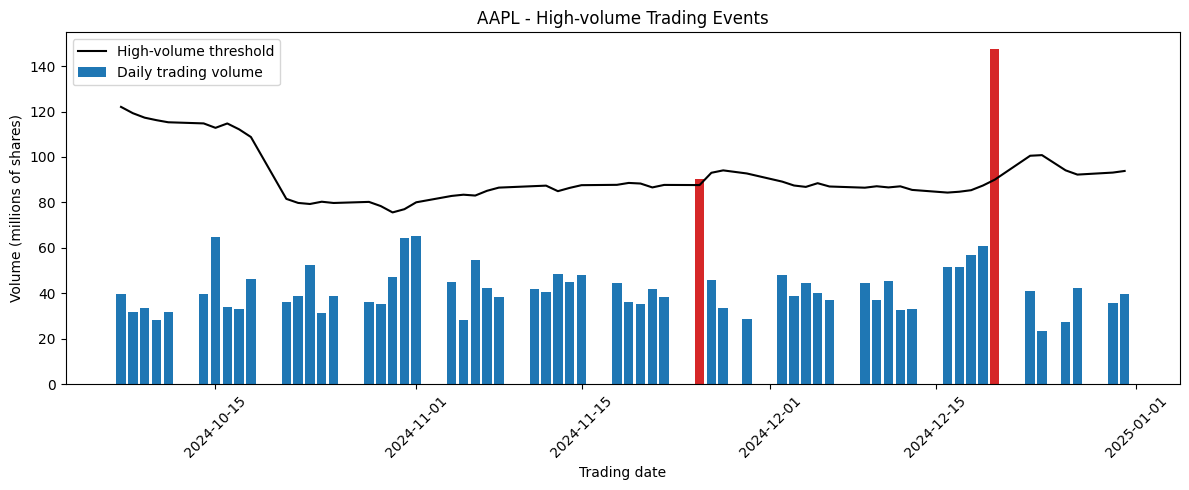

In [40]:
plt.figure(figsize=(12, 5))

plt.bar(
    worked_example_window.index,
    worked_example_window["Volume"] / 1e6,
    color=np.where(
        worked_example_window["High_volume_event"],
        "tab:red",
        "tab:blue"
    ),
    label="Daily trading volume"
)

plt.plot(
    worked_example_window.index,
    worked_example_window["Threshold"] / 1e6,
    color="black",
    label="High-volume threshold"
)

plt.title(
    f"{rfm_example_ticker} - High-volume Trading Events"
)

plt.xlabel("Trading date")
plt.ylabel("Volume (millions of shares)")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    output_dir / "rfm_worked_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
features = risk_return_features.join(
    rfm_features,
    how="left"
)

features = features.join(
    sp500_df.set_index("Yahoo_Ticker")[
        ["Security", "GICS Sector"]
    ]
)

features.index.name = "Ticker"

assert features.index.is_unique

assert len(features) == len(included)

features.head(10)

,Mean_weekly_return,Weekly_beta,Weekly_observations,Recency,Frequency,Monetary_USD,Last_event_date,Observation_date,Security,GICS Sector
Ticker,,,,,,,,,,
MMM,0.001142,0.869079,207,11,4,2.599146e+10,2024-12-20,2024-12-31,3M,Industrials
AOS,0.001991,1.042804,207,11,2,4.748980e+09,2024-12-20,2024-12-31,A. O. Smith,Industrials
ABT,0.000971,0.583543,207,11,1,3.523027e+10,2024-12-20,2024-12-31,Abbott Laboratories,Health Care
ABBV,0.003749,0.425365,207,11,3,6.837054e+10,2024-12-20,2024-12-31,AbbVie,Health Care
ACN,0.002376,1.143299,207,11,2,5.199430e+10,2024-12-20,2024-12-31,Accenture,Information Technology
ADBE,0.000990,1.553525,207,18,3,1.030403e+11,2024-12-13,2024-12-31,Adobe Inc.,Information Technology
AMD,0.003624,1.877622,207,18,4,3.131659e+11,2024-12-13,2024-12-31,Advanced Micro Devices,Information Technology
AES,-0.001420,1.143912,207,54,3,1.119578e+10,2024-11-07,2024-12-31,AES Corporation,Utilities
AFL,0.005004,0.707196,207,11,2,1.328456e+10,2024-12-20,2024-12-31,Aflac,Financials


In [42]:
feature_columns = [
    "Mean_weekly_return",
    "Weekly_beta",
    "Recency",
    "Frequency",
    "Monetary_USD"
]

valid_features = (
    features[feature_columns].notna().all(axis=1) &
    np.isfinite(features[feature_columns]).all(axis=1)
)

clustering_features = features.loc[
    valid_features
].copy()

rfm_excluded = features.loc[
    ~valid_features
].copy()

rfm_excluded["Exclusion_reason"] = np.where(
    rfm_excluded["Recency"].isna(),
    "No qualifying high-volume event",
    "Missing or invalid analytical feature"
)

print("Shares after daily validation:", len(features))

print("Additional feature-stage exclusions:",
      len(rfm_excluded))

print("Common clustering population:",
      len(clustering_features))

assert clustering_features[feature_columns].notna().all().all()

assert len(clustering_features) > 0

rfm_excluded[["Security", "Exclusion_reason"]]

Shares after daily validation: 486
Additional feature-stage exclusions: 0
Common clustering population: 486


,Security,Exclusion_reason
Ticker,,


In [43]:
feature_summary = pd.DataFrame({
    "Mean weekly return (%)":
        clustering_features["Mean_weekly_return"] * 100,

    "Weekly beta":
        clustering_features["Weekly_beta"],

    "Recency (days)":
        clustering_features["Recency"],

    "Frequency (days)":
        clustering_features["Frequency"],

    "Monetary (USD billions)":
        clustering_features["Monetary_USD"] / 1e9
}).describe().T

feature_summary.round(4)

,count,mean,std,min,25%,50%,75%,max
Mean weekly return (%),486.0,0.2857,0.2652,-0.4468,0.1182,0.2619,0.4207,1.7772
Weekly beta,486.0,0.9737,0.4073,0.0555,0.6666,0.9506,1.1795,3.7786
Recency (days),486.0,20.4074,21.3424,4.0000,11.0000,11.0000,14.7500,222.0000
Frequency (days),486.0,2.9897,1.3308,0.0000,2.0000,3.0000,4.0000,8.0000
Monetary (USD billions),486.0,39.4042,129.1388,1.2975,10.1952,16.6838,32.2769,1847.6974


In [44]:
validation_rules = pd.DataFrame([
    ["Duplicate dates", "Reject ambiguous daily date indexes"],
    ["Missing data", "No missing prices or volume for retained shares"],
    ["Unequal histories", "Require full benchmark trading calendar"],
    ["Invalid prices", "Require finite positive prices"],
    ["Volume errors", "Require finite positive trading volume"],
    ["Corporate actions", "Investigate splits and extreme movements"],
    ["Weekly alignment", "Identical consecutive Friday-ending weeks"],
    ["Boundary weeks", "Exclude incomplete study-period weeks"],
    ["High-volume threshold", "Twice the preceding 20-session mean"],
    ["Recency", "Calendar days since latest qualifying event"],
    ["Frequency", "Qualifying days within latest 60 sessions"],
    ["Monetary", "Sum of Close multiplied by Volume over 60 sessions"],
    ["No qualifying event", "Missing Recency; exclude from common clustering set"],
    ["Clustering population", "Same valid shares across comparisons"]
], columns=["Validation_check", "Rule"])

validation_rules

,Validation_check,Rule
0,Duplicate dates,Reject ambiguous daily date indexes
1,Missing data,No missing prices or volume for retained shares
2,Unequal histories,Require full benchmark trading calendar
3,Invalid prices,Require finite positive prices
4,Volume errors,Require finite positive trading volume
5,Corporate actions,Investigate splits and extreme movements
6,Weekly alignment,Identical consecutive Friday-ending weeks
7,Boundary weeks,Exclude incomplete study-period weeks
8,High-volume threshold,Twice the preceding 20-session mean
9,Recency,Calendar days since latest qualifying event


In [45]:
features.to_csv(
    output_dir / "feature_table.csv"
)

clustering_features.to_csv(
    output_dir / "clustering_features.csv"
)

rfm_excluded.to_csv(
    output_dir / "feature_exclusion_log.csv"
)

feature_summary.to_csv(
    output_dir / "feature_summary.csv"
)

validation_rules.to_csv(
    output_dir / "validation_rules_summary.csv",
    index=False
)

inclusion_log = validation_log[
    ["Security", "GICS Sector", "Status", "Exclusion_reason"]
].copy()

inclusion_log["Clustering_status"] = np.where(
    inclusion_log.index.isin(clustering_features.index),
    "Included",
    "Excluded"
)

inclusion_log["Clustering_exclusion_reason"] = (
    inclusion_log["Exclusion_reason"]
)

inclusion_log.loc[
    rfm_excluded.index,
    "Clustering_exclusion_reason"
] = rfm_excluded["Exclusion_reason"]

inclusion_log.to_csv(
    output_dir / "inclusion_log.csv"
)

print("Task 1 feature and validation outputs saved")
print("Total original tickers:", len(tickers))
print("Shares passing daily validation:", len(included))
print("Shares available for clustering:", len(clustering_features))

Task 1 feature and validation outputs saved
Total original tickers: 503
Shares passing daily validation: 486
Shares available for clustering: 486


Task 2 – Stock Segmentation and Sensitivity Analysis

2.1 Feature Preparation

In [46]:
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

In [47]:
risk_return_df = clustering_features[
    ["Mean_weekly_return", "Weekly_beta"]
].copy()

rfm_df = clustering_features[
    ["Recency", "Frequency", "Monetary_USD"]
].copy()

assert risk_return_df.index.equals(rfm_df.index)

assert risk_return_df.notna().all().all()
assert rfm_df.notna().all().all()

print("Risk and return matrix:", risk_return_df.shape)
print("Trading activity matrix:", rfm_df.shape)

display(risk_return_df.head())
display(rfm_df.head())

Risk and return matrix: (486, 2)
Trading activity matrix: (486, 3)


,Mean_weekly_return,Weekly_beta
Ticker,,
MMM,0.001142,0.869079
AOS,0.001991,1.042804
ABT,0.000971,0.583543
ABBV,0.003749,0.425365
ACN,0.002376,1.143299


,Recency,Frequency,Monetary_USD
Ticker,,,
MMM,11,4,2.599146e+10
AOS,11,2,4.748980e+09
ABT,11,1,3.523027e+10
ABBV,11,3,6.837054e+10
ACN,11,2,5.199430e+10


In [48]:
rfm_model_df = rfm_df.copy()

rfm_model_df["Log_Monetary"] = np.log1p(
    rfm_model_df["Monetary_USD"]
)

rfm_model_df = rfm_model_df.drop(
    columns="Monetary_USD"
)

diagnostic_features = risk_return_df.join(rfm_df)

diagnostic_features["Log_Monetary"] = (
    rfm_model_df["Log_Monetary"]
)

z_scores = (
    diagnostic_features - diagnostic_features.mean()
) / diagnostic_features.std(ddof=0)

skew_outlier_summary = pd.DataFrame({
    "Skewness": diagnostic_features.skew(),
    "Outliers_abs_z_above_3": (
        z_scores.abs() > 3
    ).sum()
})

skew_outlier_summary.round(3)

,Skewness,Outliers_abs_z_above_3
Mean_weekly_return,0.868,6
Weekly_beta,1.104,2
Recency,3.646,11
Frequency,0.425,5
Monetary_USD,11.684,5
Log_Monetary,1.079,7


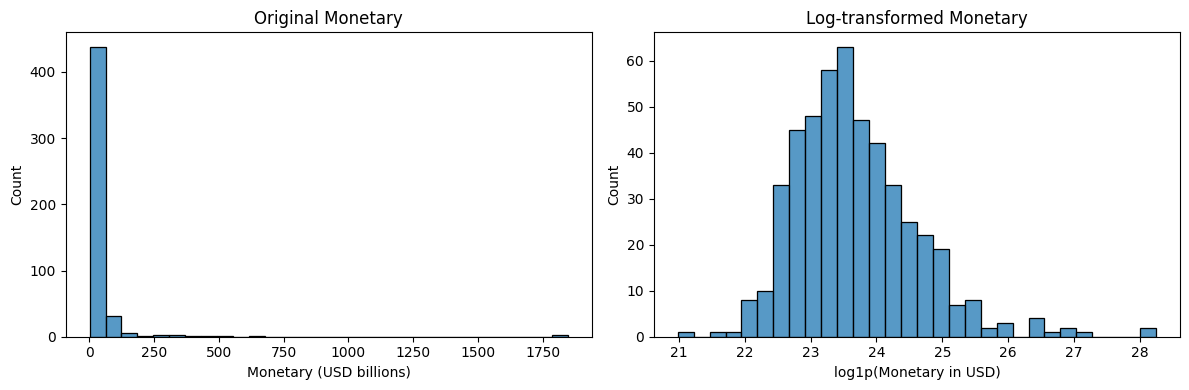

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    rfm_df["Monetary_USD"] / 1e9,
    bins=30,
    ax=axes[0]
)

axes[0].set_title("Original Monetary")
axes[0].set_xlabel("Monetary (USD billions)")

sns.histplot(
    rfm_model_df["Log_Monetary"],
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Log-transformed Monetary")
axes[1].set_xlabel("log1p(Monetary in USD)")

plt.tight_layout()

plt.savefig(
    output_dir / "monetary_transformation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
scaler_rr = StandardScaler()
scaler_rfm = StandardScaler()

X_rr = scaler_rr.fit_transform(risk_return_df)
X_rfm = scaler_rfm.fit_transform(rfm_model_df)

print("Risk and return means:",
      X_rr.mean(axis=0).round(6))

print("Risk and return standard deviations:",
      X_rr.std(axis=0).round(6))

print("RFM means:",
      X_rfm.mean(axis=0).round(6))

print("RFM standard deviations:",
      X_rfm.std(axis=0).round(6))

assert np.allclose(X_rr.mean(axis=0), 0)
assert np.allclose(X_rr.std(axis=0), 1)

assert np.allclose(X_rfm.mean(axis=0), 0)
assert np.allclose(X_rfm.std(axis=0), 1)

Risk and return means: [-0.  0.]
Risk and return standard deviations: [1. 1.]
RFM means: [-0. -0. -0.]
RFM standard deviations: [1. 1. 1.]


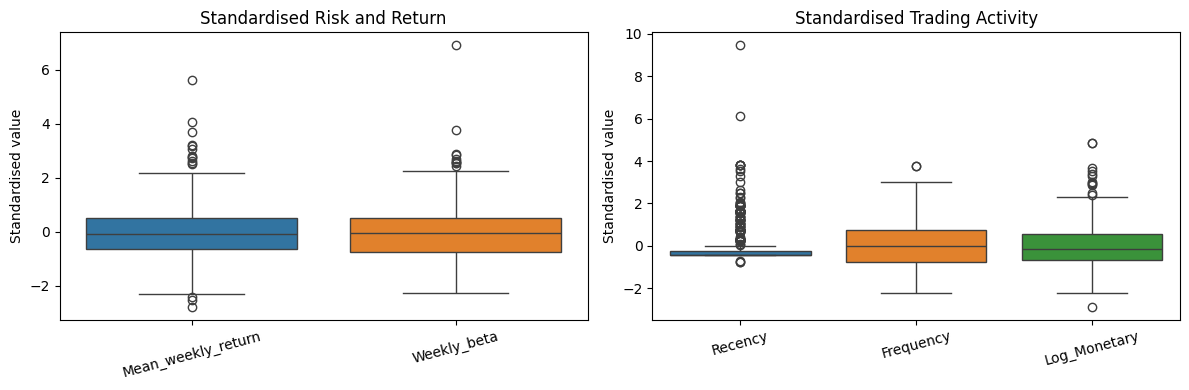

In [51]:
scaled_rr = pd.DataFrame(
    X_rr,
    index=risk_return_df.index,
    columns=risk_return_df.columns
)

scaled_rfm = pd.DataFrame(
    X_rfm,
    index=rfm_model_df.index,
    columns=rfm_model_df.columns
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=scaled_rr, ax=axes[0])
axes[0].set_title("Standardised Risk and Return")

sns.boxplot(data=scaled_rfm, ax=axes[1])
axes[1].set_title("Standardised Trading Activity")

for ax in axes:
    ax.set_ylabel("Standardised value")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()

plt.savefig(
    output_dir / "standardised_feature_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

2.2 Agglomerative Clustering

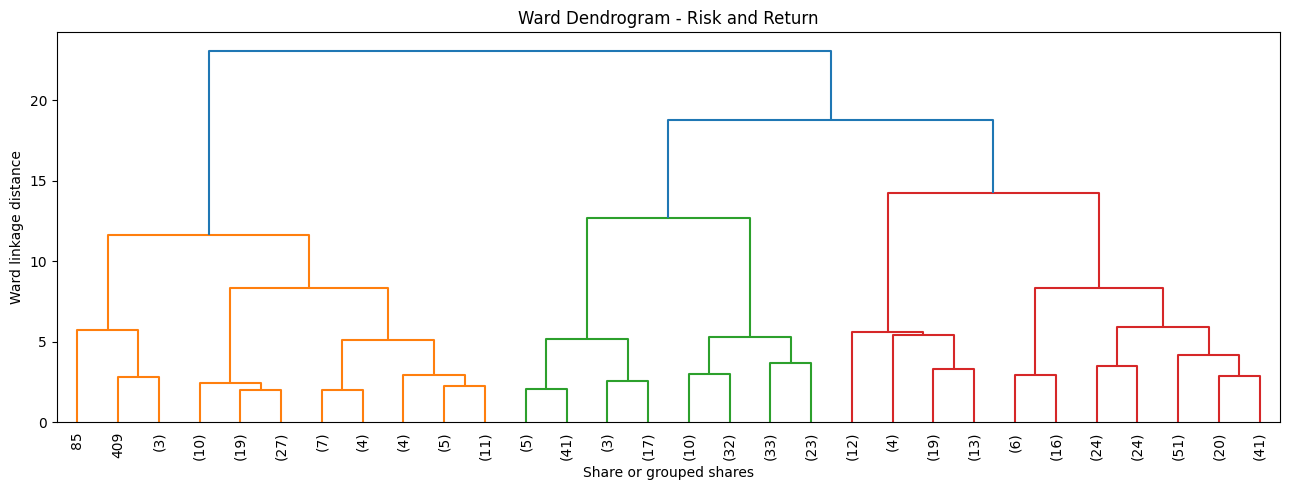

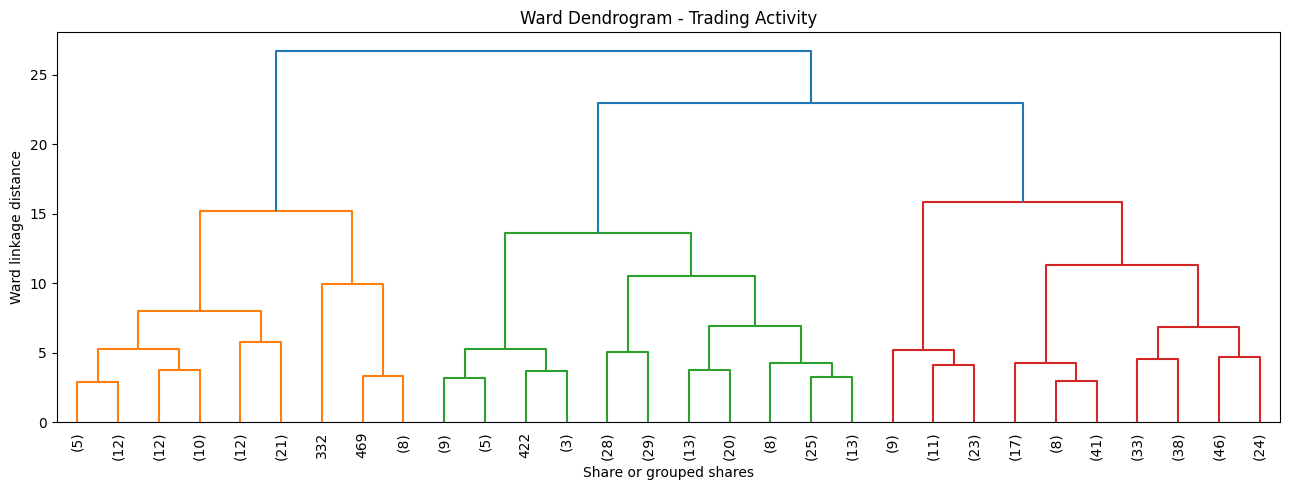

In [52]:
Z_rr = linkage(
    X_rr,
    method="ward",
    metric="euclidean"
)

Z_rfm = linkage(
    X_rfm,
    method="ward",
    metric="euclidean"
)

for hierarchy, title, filename in [
    (Z_rr, "Risk and Return", "ward_risk_return"),
    (Z_rfm, "Trading Activity", "ward_rfm")
]:

    plt.figure(figsize=(13, 5))

    dendrogram(
        hierarchy,
        truncate_mode="lastp",
        p=30,
        show_leaf_counts=True,
        leaf_rotation=90
    )

    plt.title(f"Ward Dendrogram - {title}")
    plt.xlabel("Share or grouped shares")
    plt.ylabel("Ward linkage distance")

    plt.tight_layout()

    plt.savefig(
        output_dir / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [53]:
def evaluate_ward(hierarchy, X):

    records = []
    labels_by_k = {}

    for k in range(2, 9):

        labels = cut_tree(
            hierarchy,
            n_clusters=k
        ).ravel() + 1

        sizes = pd.Series(labels).value_counts().sort_index()

        assert len(sizes) == k

        records.append({
            "k": k,
            "Silhouette": silhouette_score(X, labels),
            "Smallest_cluster": sizes.min(),
            "Largest_cluster": sizes.max(),
            "Cluster_sizes": sizes.tolist()
        })

        labels_by_k[k] = labels

    return pd.DataFrame(records).set_index("k"), labels_by_k


ward_rr_results, ward_rr_labels = evaluate_ward(
    Z_rr, X_rr
)

ward_rfm_results, ward_rfm_labels = evaluate_ward(
    Z_rfm, X_rfm
)

print("Ward - Risk and Return")
display(ward_rr_results.round(4))

print("Ward - Trading Activity")
display(ward_rfm_results.round(4))

Ward - Risk and Return


,Silhouette,Smallest_cluster,Largest_cluster,Cluster_sizes
k,,,,
2,0.3395,92,394,"[394, 92]"
3,0.2738,92,230,"[230, 164, 92]"
4,0.2821,48,182,"[182, 164, 48, 92]"
5,0.3041,48,182,"[182, 66, 98, 48, 92]"
6,0.3204,5,182,"[182, 66, 98, 48, 87, 5]"
7,0.3240,5,160,"[160, 66, 98, 48, 22, 87, 5]"
8,0.3208,5,160,"[160, 66, 98, 48, 22, 56, 31, 5]"


Ward - Trading Activity


,Silhouette,Smallest_cluster,Largest_cluster,Cluster_sizes
k,,,,
2,0.3680,82,404,"[404, 82]"
3,0.3040,82,250,"[154, 250, 82]"
4,0.2888,43,207,"[154, 207, 82, 43]"
5,0.3050,10,207,"[154, 207, 72, 43, 10]"
6,0.3144,10,207,"[136, 207, 18, 72, 43, 10]"
7,0.2917,10,141,"[136, 66, 18, 72, 141, 43, 10]"
8,0.3021,10,141,"[57, 66, 79, 18, 72, 141, 43, 10]"


In [54]:
def candidate_profiles(original_data, labels_by_k):

    profiles = []

    for k, labels in labels_by_k.items():

        grouped = original_data.assign(
            Cluster=labels
        ).groupby("Cluster")

        profile = grouped.mean()

        profile.insert(0, "Shares", grouped.size())
        profile.insert(0, "k", k)

        profiles.append(profile.reset_index())

    return pd.concat(profiles, ignore_index=True)


rr_original_units = risk_return_df.copy()

rr_original_units["Mean_weekly_return"] *= 100

rr_original_units = rr_original_units.rename(
    columns={"Mean_weekly_return": "Mean_return_pct"}
)

rfm_original_units = rfm_df.copy()

rfm_original_units["Monetary_USD"] /= 1e9

rfm_original_units = rfm_original_units.rename(
    columns={"Monetary_USD": "Monetary_USD_bn"}
)

ward_rr_profiles = candidate_profiles(
    rr_original_units,
    ward_rr_labels
)

ward_rfm_profiles = candidate_profiles(
    rfm_original_units,
    ward_rfm_labels
)

print("Ward Risk and Return - Candidate Profiles")
display(ward_rr_profiles.round(4))

print("Ward RFM - Candidate Profiles")
display(ward_rfm_profiles.round(3))

Ward Risk and Return - Candidate Profiles


,Cluster,k,Shares,Mean_return_pct,Weekly_beta
0,1,2,394,0.2048,0.8979
1,2,2,92,0.6321,1.2981
2,1,3,230,0.1459,1.1096
3,2,3,164,0.2875,0.6012
4,3,3,92,0.6321,1.2981
5,1,4,182,0.1317,0.9728
6,2,4,164,0.2875,0.6012
7,3,4,48,0.1999,1.6280
8,4,4,92,0.6321,1.2981
9,1,5,182,0.1317,0.9728


Ward RFM - Candidate Profiles


,Cluster,k,Shares,Recency,Frequency,Monetary_USD_bn
0,1,2,404,12.715,3.171,37.830
1,2,2,82,58.305,2.098,47.159
2,1,3,154,13.682,2.864,80.145
3,2,3,250,12.120,3.360,11.764
4,3,3,82,58.305,2.098,47.159
5,1,4,154,13.682,2.864,80.145
6,2,4,207,11.140,2.942,11.100
7,3,4,82,58.305,2.098,47.159
8,4,4,43,16.837,5.372,14.962
9,1,5,154,13.682,2.864,80.145


2.3 K-means Clustering

In [55]:
def evaluate_kmeans(X):

    records = []
    labels_by_k = {}

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            random_state=42,
            n_init=50
        )

        labels = model.fit_predict(X) + 1

        sizes = pd.Series(labels).value_counts().sort_index()

        assert len(sizes) == k

        records.append({
            "k": k,
            "Silhouette": silhouette_score(X, labels),
            "Inertia": model.inertia_,
            "Smallest_cluster": sizes.min(),
            "Largest_cluster": sizes.max(),
            "Cluster_sizes": sizes.tolist()
        })

        labels_by_k[k] = labels

    return pd.DataFrame(records).set_index("k"), labels_by_k


km_rr_results, km_rr_labels = evaluate_kmeans(X_rr)

km_rfm_results, km_rfm_labels = evaluate_kmeans(X_rfm)

print("K-means - Risk and Return")
display(km_rr_results.round(4))

print("K-means - Trading Activity")
display(km_rfm_results.round(4))

K-means - Risk and Return


,Silhouette,Inertia,Smallest_cluster,Largest_cluster,Cluster_sizes
k,,,,,
2,0.3869,621.6344,143,343,"[143, 343]"
3,0.3289,461.1787,119,202,"[202, 165, 119]"
4,0.3270,371.5771,40,160,"[132, 154, 40, 160]"
5,0.3406,309.6130,27,166,"[112, 166, 131, 27, 50]"
6,0.3349,265.0970,5,156,"[156, 127, 50, 105, 43, 5]"
7,0.3285,227.1825,5,128,"[103, 85, 41, 128, 77, 47, 5]"
8,0.3542,194.3616,5,136,"[136, 43, 76, 78, 5, 29, 40, 79]"


K-means - Trading Activity


,Silhouette,Inertia,Smallest_cluster,Largest_cluster,Cluster_sizes
k,,,,,
2,0.4231,1066.8319,68,418,"[418, 68]"
3,0.3250,796.6144,64,270,"[270, 152, 64]"
4,0.3409,609.8325,61,212,"[122, 61, 212, 91]"
5,0.3578,514.7136,11,198,"[68, 122, 87, 11, 198]"
6,0.3467,437.3931,11,143,"[105, 143, 40, 11, 120, 67]"
7,0.3474,386.2862,1,141,"[141, 41, 104, 120, 1, 68, 11]"
8,0.3503,342.1749,1,140,"[15, 106, 64, 66, 1, 11, 140, 83]"


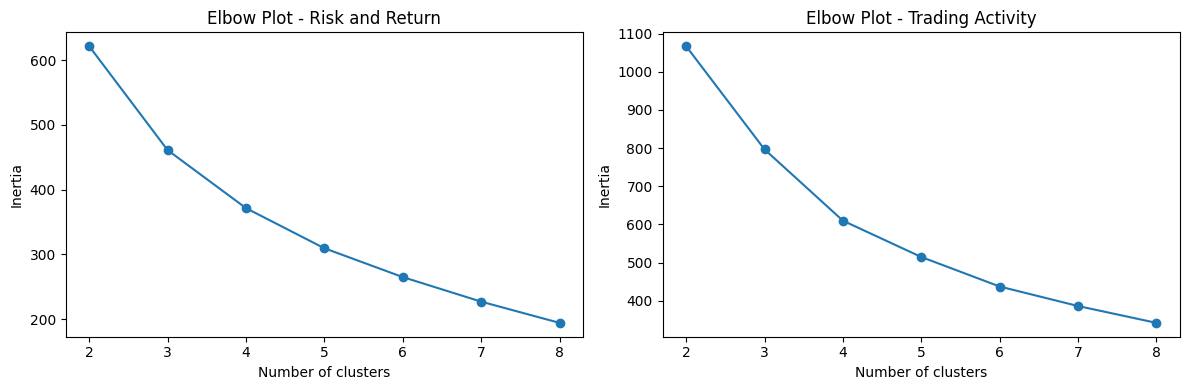

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    km_rr_results.index,
    km_rr_results["Inertia"],
    marker="o"
)

axes[0].set_title("Elbow Plot - Risk and Return")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    km_rfm_results.index,
    km_rfm_results["Inertia"],
    marker="o"
)

axes[1].set_title("Elbow Plot - Trading Activity")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Inertia")

for ax in axes:
    ax.set_xticks(range(2, 9))

plt.tight_layout()

plt.savefig(
    output_dir / "kmeans_elbow_plots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

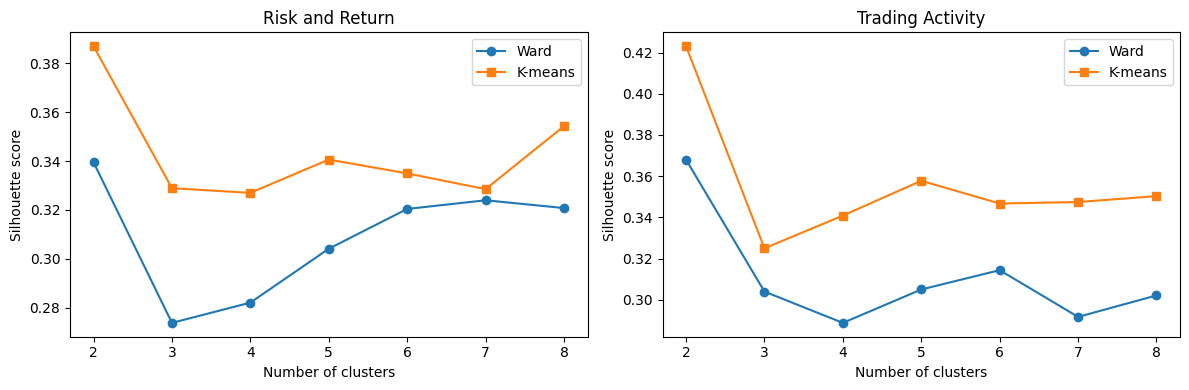

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, ward_results, km_results, title in [
    (axes[0], ward_rr_results, km_rr_results,
     "Risk and Return"),

    (axes[1], ward_rfm_results, km_rfm_results,
     "Trading Activity")
]:

    ax.plot(
        ward_results.index,
        ward_results["Silhouette"],
        marker="o",
        label="Ward"
    )

    ax.plot(
        km_results.index,
        km_results["Silhouette"],
        marker="s",
        label="K-means"
    )

    ax.set_title(title)
    ax.set_xlabel("Number of clusters")
    ax.set_ylabel("Silhouette score")
    ax.set_xticks(range(2, 9))
    ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
km_rr_profiles = candidate_profiles(
    rr_original_units,
    km_rr_labels
)

km_rfm_profiles = candidate_profiles(
    rfm_original_units,
    km_rfm_labels
)

print("K-means Risk and Return - Candidate Profiles")
display(km_rr_profiles.round(4))

print("K-means RFM - Candidate Profiles")
display(km_rfm_profiles.round(3))

K-means Risk and Return - Candidate Profiles


,Cluster,k,Shares,Mean_return_pct,Weekly_beta
0,1,2,143,0.5330,1.3505
1,2,2,343,0.1826,0.8166
2,1,3,202,0.2593,0.6308
3,2,3,165,0.0946,1.1391
4,3,3,119,0.5955,1.3264
5,1,4,132,0.0842,1.2030
6,2,4,154,0.1690,0.5766
7,3,4,40,0.7253,1.7085
8,4,4,160,0.4544,0.9830
9,1,5,112,0.0344,1.0200


K-means RFM - Candidate Profiles


,Cluster,k,Shares,Recency,Frequency,Monetary_USD_bn
0,1,2,418,13.423,3.187,32.691
1,2,2,68,63.338,1.779,80.671
2,1,3,270,13.367,3.352,12.014
3,2,3,152,14.303,2.895,81.729
4,3,3,64,64.609,1.688,54.435
5,1,4,122,13.943,4.549,15.015
6,2,4,61,66.016,1.672,56.180
7,3,4,212,13.264,2.368,15.175
8,4,4,91,15.143,3.231,117.301
9,1,5,68,50.647,2.191,26.437


In [59]:
selected_k = {
    "Ward_RR": 2,
    "Ward_RFM": 2,
    "KMeans_RR": 2,
    "KMeans_RFM": 2
}

model_results = {
    "Ward_RR": ward_rr_results,
    "Ward_RFM": ward_rfm_results,
    "KMeans_RR": km_rr_results,
    "KMeans_RFM": km_rfm_results
}

selection_summary = pd.DataFrame([
    {
        "Model": model,
        "Selected_k": k,
        "Silhouette": model_results[model].loc[k, "Silhouette"],
        "Smallest_cluster": model_results[model].loc[k, "Smallest_cluster"],
        "Largest_cluster": model_results[model].loc[k, "Largest_cluster"]
    }
    for model, k in selected_k.items()
]).set_index("Model")

selection_summary.round(4)

,Selected_k,Silhouette,Smallest_cluster,Largest_cluster
Model,,,,
Ward_RR,2,0.3395,92,394
Ward_RFM,2,0.3680,82,404
KMeans_RR,2,0.3869,143,343
KMeans_RFM,2,0.4231,68,418


2.4 Cluster Profiles and Algorithm Comparison

In [60]:
assignments = pd.DataFrame({
    "Ward_RR":
        ward_rr_labels[selected_k["Ward_RR"]],

    "Ward_RFM":
        ward_rfm_labels[selected_k["Ward_RFM"]],

    "KMeans_RR":
        km_rr_labels[selected_k["KMeans_RR"]],

    "KMeans_RFM":
        km_rfm_labels[selected_k["KMeans_RFM"]]

}, index=clustering_features.index)

assignments.index.name = "Ticker"

assert assignments.index.equals(clustering_features.index)
assert assignments.notna().all().all()

for model, k in selected_k.items():

    assert assignments[model].nunique() == k

print("Shares assigned:", len(assignments))

assignments.head(10)

Shares assigned: 486


,Ward_RR,Ward_RFM,KMeans_RR,KMeans_RFM
Ticker,,,,
MMM,1,1,2,1
AOS,1,1,2,1
ABT,1,1,2,1
ABBV,1,1,2,1
ACN,1,1,2,1
ADBE,1,1,1,1
AMD,1,1,1,1
AES,1,2,2,2
AFL,1,1,2,1


In [61]:
profile_data = rr_original_units.join(
    rfm_original_units
)

def final_cluster_profile(labels):

    grouped = profile_data.assign(
        Cluster=labels
    ).groupby("Cluster")

    profile = grouped.mean()

    profile.insert(0, "Shares", grouped.size())

    profile["Median_Monetary_USD_bn"] = (
        grouped["Monetary_USD_bn"].median()
    )

    return profile


final_profiles = {}

for model in selected_k:

    final_profiles[model] = final_cluster_profile(
        assignments[model]
    )

    print(model)
    display(final_profiles[model].round(4))

Ward_RR


,Shares,Mean_return_pct,Weekly_beta,Recency,Frequency,Monetary_USD_bn,Median_Monetary_USD_bn
Cluster,,,,,,,
1,394,0.2048,0.8979,19.6447,2.9416,30.2096,15.3252
2,92,0.6321,1.2981,23.6739,3.1957,78.7809,24.1841


Ward_RFM


,Shares,Mean_return_pct,Weekly_beta,Recency,Frequency,Monetary_USD_bn,Median_Monetary_USD_bn
Cluster,,,,,,,
1,404,0.2857,0.9666,12.7153,3.1708,37.8302,16.0473
2,82,0.2860,1.0089,58.3049,2.0976,47.1590,17.8490


KMeans_RR


,Shares,Mean_return_pct,Weekly_beta,Recency,Frequency,Monetary_USD_bn,Median_Monetary_USD_bn
Cluster,,,,,,,
1,143,0.5330,1.3505,22.6364,3.1469,81.4384,25.5237
2,343,0.1826,0.8166,19.4781,2.9242,21.8797,14.2056


KMeans_RFM


,Shares,Mean_return_pct,Weekly_beta,Recency,Frequency,Monetary_USD_bn,Median_Monetary_USD_bn
Cluster,,,,,,,
1,418,0.2830,0.9723,13.4234,3.1866,32.6910,15.5696
2,68,0.3022,0.9823,63.3382,1.7794,80.6706,22.2500


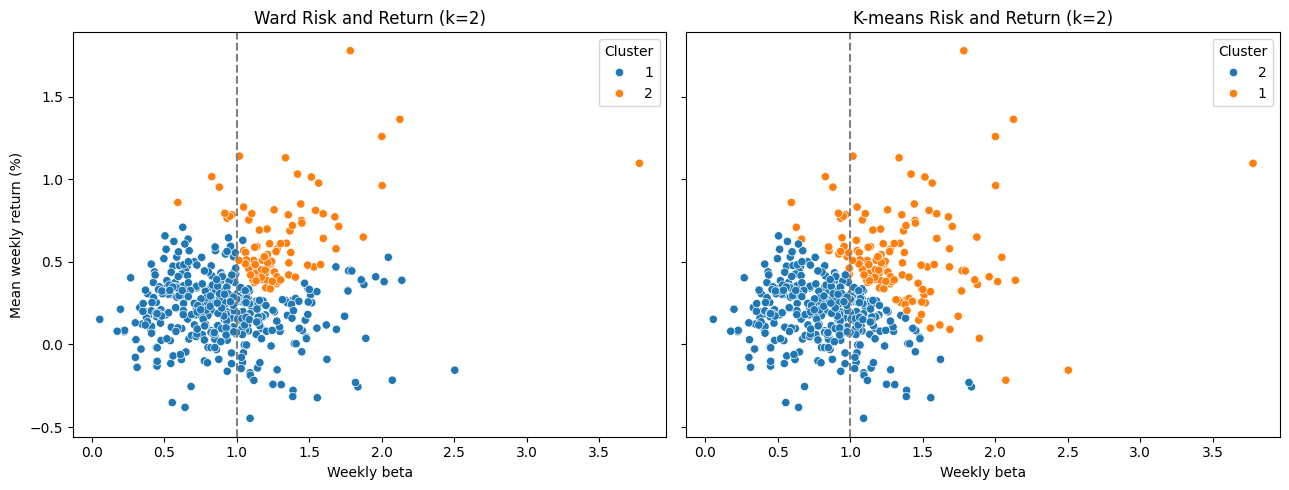

In [62]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True
)

for ax, model, title in [
    (axes[0], "Ward_RR", "Ward"),
    (axes[1], "KMeans_RR", "K-means")
]:

    sns.scatterplot(
        x=clustering_features["Weekly_beta"],
        y=clustering_features["Mean_weekly_return"] * 100,
        hue=assignments[model].astype(str),
        palette="tab10",
        ax=ax
    )

    ax.axvline(
        1,
        linestyle="--",
        color="grey"
    )

    ax.set_title(
        f"{title} Risk and Return (k={selected_k[model]})"
    )

    ax.set_xlabel("Weekly beta")
    ax.set_ylabel("Mean weekly return (%)")

    ax.legend(title="Cluster")

plt.tight_layout()

plt.savefig(
    output_dir / "risk_return_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Total explained variance: 79.44 %


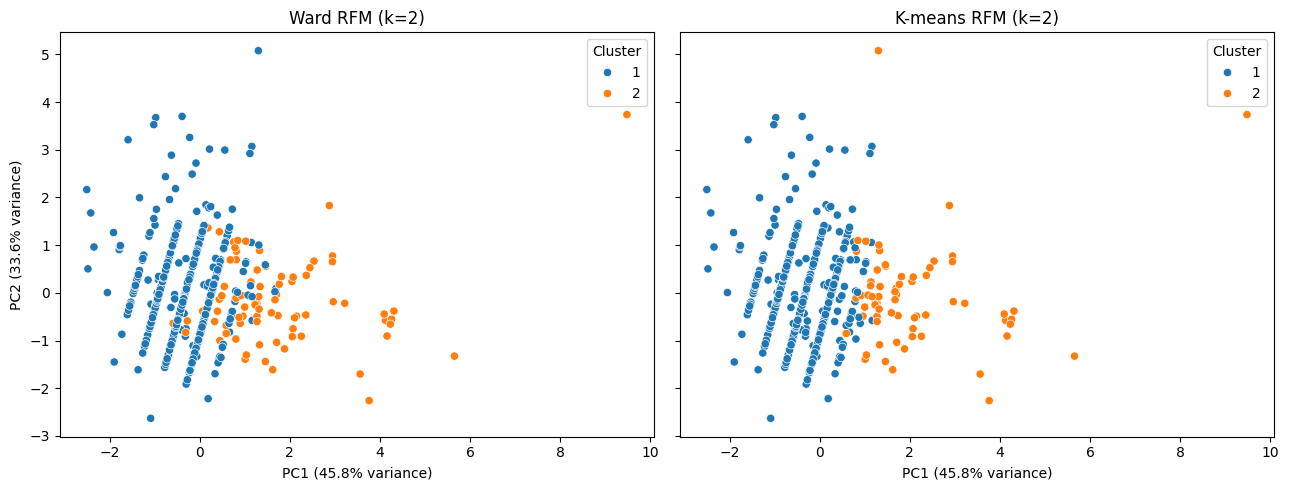

In [63]:
pca_rfm = PCA(n_components=2)
rfm_projection = pca_rfm.fit_transform(X_rfm)
explained_variance = pca_rfm.explained_variance_ratio_

pca_scores = pd.DataFrame(
    rfm_projection,
    index=rfm_model_df.index,
    columns=["PC1", "PC2"]
)

print("Total explained variance:", round(explained_variance.sum() * 100, 2), "%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for ax, model, title in [
    (axes[0], "Ward_RFM", "Ward"),
    (axes[1], "KMeans_RFM", "K-means")
]:
    sns.scatterplot(
        x=pca_scores["PC1"],
        y=pca_scores["PC2"],
        hue=assignments[model].astype(str),
        palette="tab10",
        ax=ax
    )

    ax.set_title(f"{title} RFM (k={selected_k[model]})")
    ax.set_xlabel(f"PC1 ({explained_variance[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({explained_variance[1]:.1%} variance)")
    ax.legend(title="Cluster")

plt.tight_layout()
plt.savefig(output_dir / "rfm_clusters_pca.png", dpi=300, bbox_inches="tight")
plt.show()

In [64]:
ari_rr = adjusted_rand_score(
    assignments["Ward_RR"],
    assignments["KMeans_RR"]
)

ari_rfm = adjusted_rand_score(
    assignments["Ward_RFM"],
    assignments["KMeans_RFM"]
)

comparison_rr = pd.crosstab(
    assignments["Ward_RR"],
    assignments["KMeans_RR"],
    rownames=["Ward"],
    colnames=["K-means"]
)

comparison_rfm = pd.crosstab(
    assignments["Ward_RFM"],
    assignments["KMeans_RFM"],
    rownames=["Ward"],
    colnames=["K-means"]
)

print("Risk and Return ARI:", round(ari_rr, 4))
display(comparison_rr)

print("RFM ARI:", round(ari_rfm, 4))
display(comparison_rfm)

Risk and Return ARI: 0.5976


K-means,1,2
Ward,,
1,51,343
2,92,0


RFM ARI: 0.6998


K-means,1,2
Ward,,
1,396,8
2,22,60


In [65]:
algorithm_comparison = pd.DataFrame({
    "Feature_set": [
        "Risk and Return",
        "Trading Activity"
    ],

    "Ward_k": [
        selected_k["Ward_RR"],
        selected_k["Ward_RFM"]
    ],

    "KMeans_k": [
        selected_k["KMeans_RR"],
        selected_k["KMeans_RFM"]
    ],

    "Ward_silhouette": [
        ward_rr_results.loc[
            selected_k["Ward_RR"], "Silhouette"
        ],
        ward_rfm_results.loc[
            selected_k["Ward_RFM"], "Silhouette"
        ]
    ],

    "KMeans_silhouette": [
        km_rr_results.loc[
            selected_k["KMeans_RR"], "Silhouette"
        ],
        km_rfm_results.loc[
            selected_k["KMeans_RFM"], "Silhouette"
        ]
    ],

    "Adjusted_Rand_Index": [
        ari_rr,
        ari_rfm
    ]
})

algorithm_comparison.round(4)

,Feature_set,Ward_k,KMeans_k,Ward_silhouette,KMeans_silhouette,Adjusted_Rand_Index
0,Risk and Return,2,2,0.3395,0.3869,0.5976
1,Trading Activity,2,2,0.3680,0.4231,0.6998


2.5 RFM Sensitivity and Correlated Inputs

2.5.1 Correlation Analysis

,Recency,Frequency,Log_Monetary
Recency,1.0000,-0.3463,0.1524
Frequency,-0.3463,1.0000,0.0128
Log_Monetary,0.1524,0.0128,1.0000


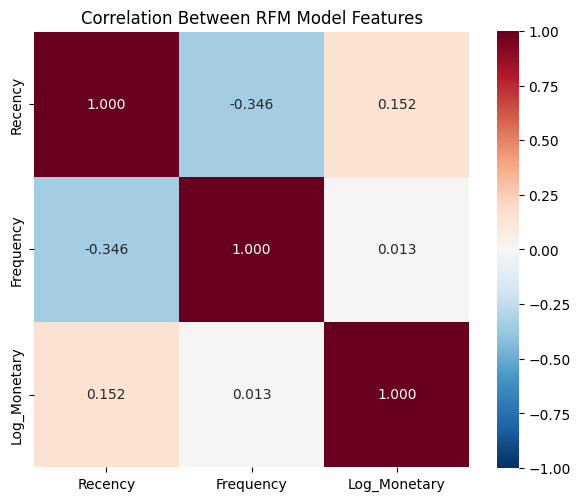

In [66]:
rfm_correlation = rfm_model_df.corr(method="pearson")
display(rfm_correlation.round(4))

plt.figure(figsize=(6, 5))

sns.heatmap(
    rfm_correlation,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between RFM Model Features")
plt.tight_layout()
plt.savefig(output_dir / "rfm_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

2.5.2 Removal of Monetary

In [67]:
rf_model_df = rfm_df[
    ["Recency", "Frequency"]
].copy()

assert rf_model_df.index.equals(
    rfm_model_df.index
)

scaler_rf = StandardScaler()

X_rf = scaler_rf.fit_transform(
    rf_model_df
)

Z_rf = linkage(
    X_rf,
    method="ward",
    metric="euclidean"
)

rf_k = selected_k["Ward_RFM"]

rf_labels = cut_tree(
    Z_rf,
    n_clusters=rf_k
).ravel() + 1

assignments["Ward_RF_only"] = rf_labels

assert assignments["Ward_RF_only"].nunique() == rf_k

print("Shares:", len(rf_model_df))
print("Number of clusters:", rf_k)

print("R and F only cluster sizes:")

assignments["Ward_RF_only"].value_counts().sort_index()

Shares: 486
Number of clusters: 2
R and F only cluster sizes:


,count
Ward_RF_only,
1,397
2,89


In [68]:
monetary_removal_ari = adjusted_rand_score(
    assignments["Ward_RFM"],
    assignments["Ward_RF_only"]
)

monetary_membership_comparison = pd.crosstab(
    assignments["Ward_RFM"],
    assignments["Ward_RF_only"],
    rownames=["Full RFM"],
    colnames=["R and F only"]
)

print("Shares compared:", len(assignments))

print("Cluster count:", rf_k)

print("Adjusted Rand Index:",
      round(monetary_removal_ari, 4))

monetary_membership_comparison

Shares compared: 486
Cluster count: 2
Adjusted Rand Index: 0.8735


R and F only,1,2
Full RFM,,
1,394,10
2,3,79


In [69]:
final_profiles["Ward_RF_only"] = final_cluster_profile(
    assignments["Ward_RF_only"]
)

sensitivity_columns = [
    "Shares",
    "Recency",
    "Frequency",
    "Monetary_USD_bn",
    "Median_Monetary_USD_bn"
]

sensitivity_profiles = pd.concat({

    "Full RFM":
        final_profiles["Ward_RFM"][
            sensitivity_columns
        ],

    "R and F only":
        final_profiles["Ward_RF_only"][
            sensitivity_columns
        ]

}, names=["Solution", "Cluster"])

sensitivity_profiles.round(3)

Shares  Recency  Frequency  Monetary_USD_bn  \
Solution     Cluster                                                
Full RFM     1           404   12.715      3.171           37.830   
             2            82   58.305      2.098           47.159   
R and F only 1           397   12.302      3.209           37.807   
             2            89   56.562      2.011           46.530   

                      Median_Monetary_USD_bn  
Solution     Cluster                          
Full RFM     1                        16.047  
             2                        17.849  
R and F only 1                        15.464  
             2                        20.848

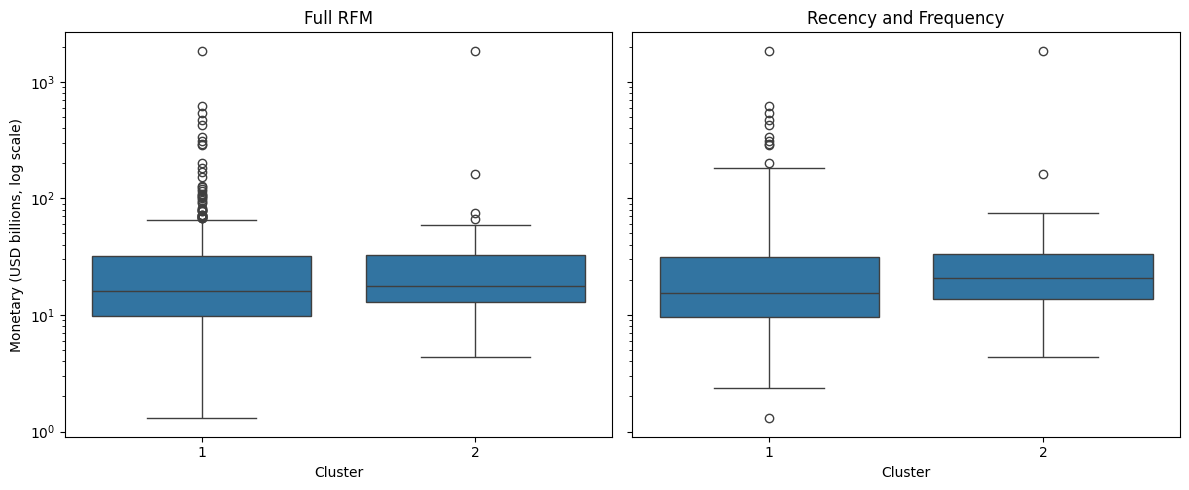

In [70]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True
)

for ax, model, title in [

    (axes[0], "Ward_RFM", "Full RFM"),

    (axes[1], "Ward_RF_only", "Recency and Frequency")

]:

    sns.boxplot(
        x=assignments[model].astype(str),
        y=rfm_original_units["Monetary_USD_bn"],
        ax=ax
    )

    ax.set_yscale("log")

    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Monetary (USD billions, log scale)")

plt.tight_layout()

plt.savefig(
    output_dir / "monetary_removal_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
all_candidate_results = pd.concat(model_results, names=["Model", "k"])

all_candidate_profiles = pd.concat({
    "Ward_RR": ward_rr_profiles,
    "Ward_RFM": ward_rfm_profiles,
    "KMeans_RR": km_rr_profiles,
    "KMeans_RFM": km_rfm_profiles
}, names=["Model", "Row"])

all_candidate_results.to_csv(output_dir / "clustering_evaluation.csv")
all_candidate_profiles.to_csv(output_dir / "candidate_cluster_profiles.csv")
selection_summary.to_csv(output_dir / "selected_cluster_counts.csv")

pd.concat(final_profiles, names=["Model", "Cluster"]).to_csv(
    output_dir / "final_cluster_profiles.csv"
)

algorithm_comparison.to_csv(output_dir / "algorithm_comparison.csv", index=False)
rfm_correlation.to_csv(output_dir / "rfm_correlation.csv")
sensitivity_profiles.to_csv(output_dir / "monetary_removal_profiles.csv")
monetary_membership_comparison.to_csv(output_dir / "monetary_removal_membership.csv")

pd.DataFrame({
    "Shares": [len(assignments)],
    "k": [rf_k],
    "ARI": [monetary_removal_ari]
}).to_csv(output_dir / "monetary_removal_summary.csv", index=False)

feature_table_with_clusters = clustering_features.join(assignments)
feature_table_with_clusters.to_csv(output_dir / "feature_table_with_clusters.csv")

print("Task 2 analytical outputs saved successfully")
print("Shares:", len(feature_table_with_clusters))
print("Baseline clustering solutions:", len(selected_k))
print("Sensitivity solutions: 1")

Task 2 analytical outputs saved successfully
Shares: 486
Baseline clustering solutions: 4
Sensitivity solutions: 1


Task 3 – Business Intelligence and Critical Review

3.2.1 Cluster Profiles and Sector Composition

In [72]:
sector_data = feature_table_with_clusters["GICS Sector"]

assert sector_data.notna().all()

sector_counts = {}
sector_composition = {}

for model in selected_k:

    counts = pd.crosstab(
        assignments[model],
        sector_data
    )

    percentages = counts.div(
        counts.sum(axis=1),
        axis=0
    ) * 100

    sector_counts[model] = counts
    sector_composition[model] = percentages

    print(model)
    display(percentages.round(2))

Ward_RR


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RR,,,,,,,,,,,
1,3.81,9.14,8.12,4.06,15.48,14.21,14.47,11.42,5.08,6.85,7.36
2,5.43,11.96,0.00,4.35,14.13,2.17,22.83,31.52,3.26,3.26,1.09


Ward_RFM


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
1,3.96,9.41,6.19,4.46,15.84,12.13,17.82,13.86,3.71,7.43,5.20
2,4.88,10.98,8.54,2.44,12.20,10.98,7.32,21.95,9.76,0.00,10.98


KMeans_RR


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RR,,,,,,,,,,,
1,3.50,16.08,0.70,6.29,11.89,1.40,20.28,33.57,2.80,2.10,1.40
2,4.37,7.00,9.04,3.21,16.62,16.33,14.29,7.58,5.54,7.87,8.16


KMeans_RFM


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
1,4.31,9.33,6.46,4.55,15.31,11.96,17.46,14.35,4.07,7.18,5.02
2,2.94,11.76,7.35,1.47,14.71,11.76,7.35,20.59,8.82,0.00,13.24


In [73]:
overall_sector_distribution = pd.DataFrame({
    "Shares": sector_data.value_counts(),
    "Percentage": sector_data.value_counts(
        normalize=True
    ) * 100
})

overall_sector_distribution.round(2)

,Shares,Percentage
GICS Sector,,
Industrials,78,16.05
Information Technology,74,15.23
Financials,74,15.23
Health Care,58,11.93
Consumer Discretionary,47,9.67
Consumer Staples,32,6.58
Utilities,30,6.17
Real Estate,30,6.17
Materials,23,4.73


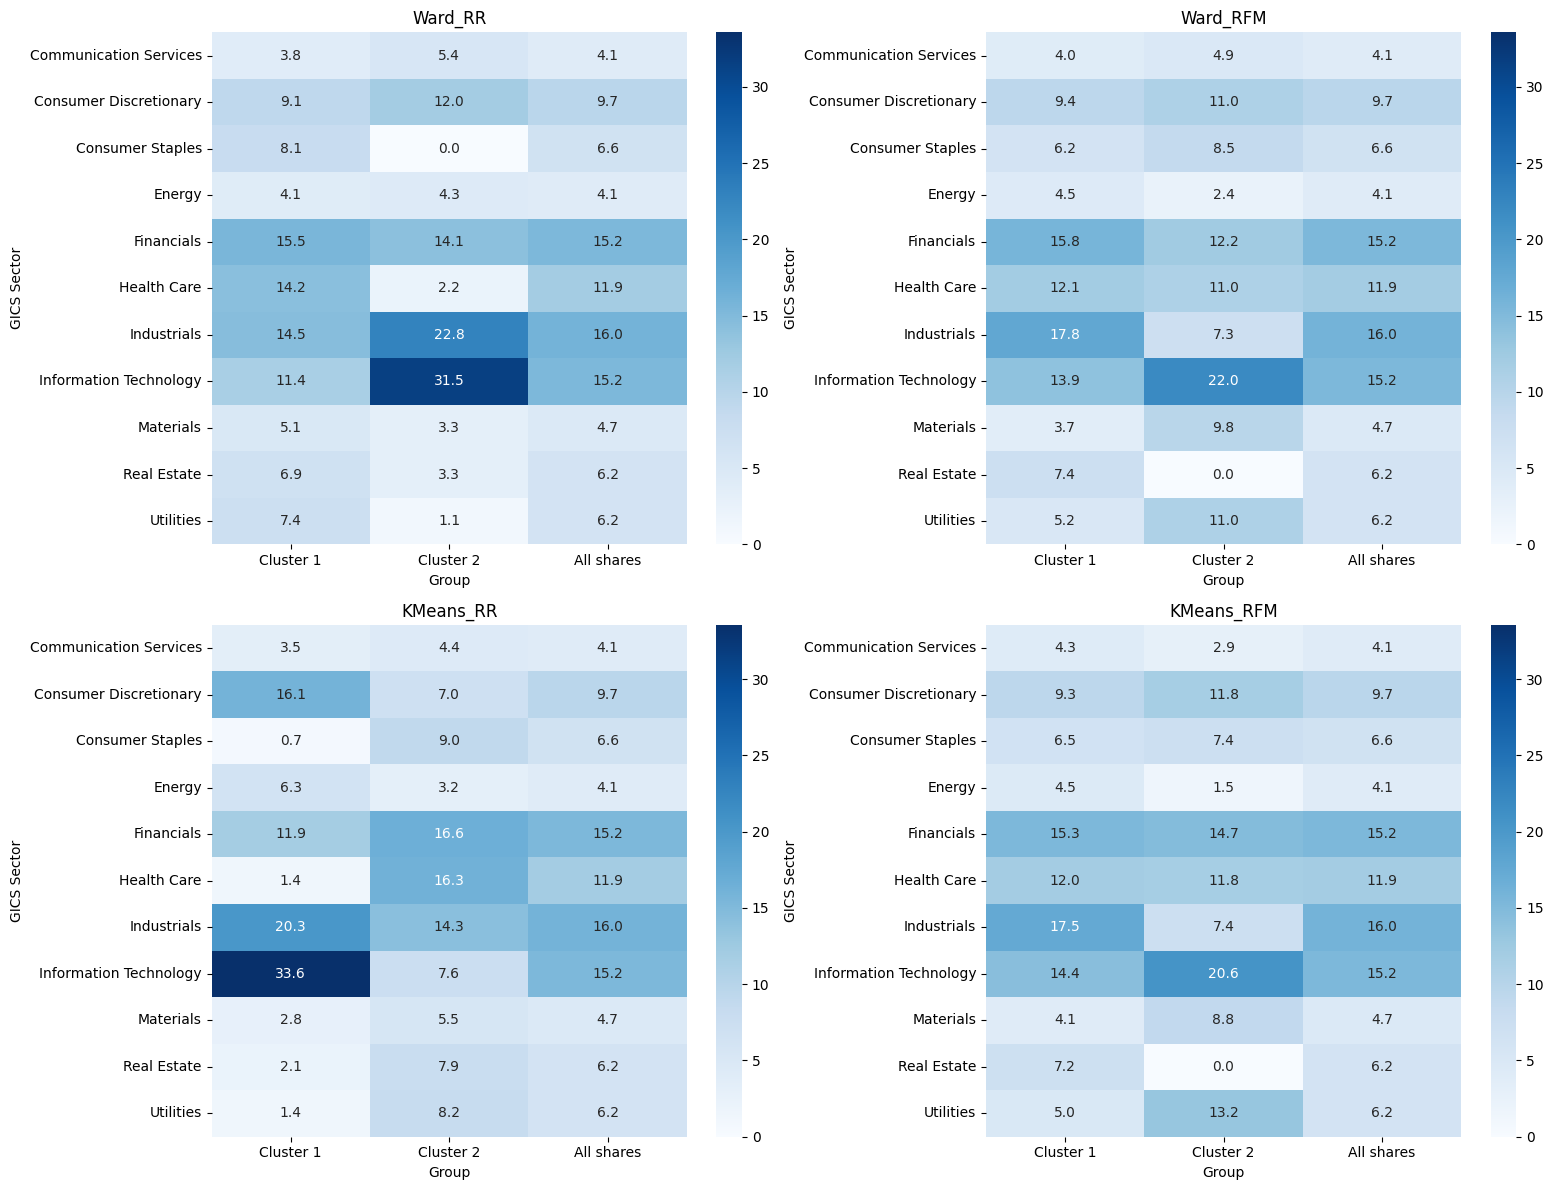

In [74]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 12)
)

for ax, model in zip(axes.ravel(), selected_k):

    composition = sector_composition[model].T

    composition.columns = [
        f"Cluster {c}" for c in composition.columns
    ]

    composition["All shares"] = (
        overall_sector_distribution["Percentage"]
    )

    sns.heatmap(
        composition,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=max(
            table.to_numpy().max()
            for table in sector_composition.values()
        ),
        ax=ax
    )

    ax.set_title(model)
    ax.set_xlabel("Group")
    ax.set_ylabel("GICS Sector")

plt.tight_layout()

plt.savefig(
    output_dir / "sector_composition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [75]:
cross_segmentation = {}
cross_segmentation_ari = {}

for algorithm in ["Ward", "KMeans"]:

    rr_labels = assignments[f"{algorithm}_RR"]
    rfm_labels = assignments[f"{algorithm}_RFM"]

    cross_segmentation[algorithm] = pd.crosstab(
        rr_labels,
        rfm_labels,
        rownames=["Risk and Return"],
        colnames=["RFM"]
    )

    cross_segmentation_ari[algorithm] = (
        adjusted_rand_score(rr_labels, rfm_labels)
    )

    print(algorithm)

    print(
        "Cross-segmentation ARI:",
        round(cross_segmentation_ari[algorithm], 4)
    )

    display(cross_segmentation[algorithm])

Ward
Cross-segmentation ARI: 0.0285


RFM,1,2
Risk and Return,,
1,331,63
2,73,19


KMeans
Cross-segmentation ARI: 0.0045


RFM,1,2
Risk and Return,,
1,122,21
2,296,47


3.2.3 Critical Evaluation and Limitations

In [76]:
review_returns = weekly_returns.loc[
    :, assignments.index
]

assert review_returns.columns.equals(
    assignments.index
)

return_correlations = review_returns.corr()

pair_rows, pair_cols = np.triu_indices(
    len(assignments),
    k=1
)

pair_correlations = return_correlations.to_numpy()[
    pair_rows, pair_cols
]

print("Shares:", review_returns.shape[1])
print("Weekly observations:", review_returns.shape[0])
print("Unique share pairs:", len(pair_correlations))

print(
    "Mean pairwise return correlation:",
    round(pair_correlations.mean(), 4)
)

print(
    "Median pairwise return correlation:",
    round(np.median(pair_correlations), 4)
)

Shares: 486
Weekly observations: 207
Unique share pairs: 117855
Mean pairwise return correlation: 0.2995
Median pairwise return correlation: 0.2989


In [77]:
dependency_records = []

groupings = {
    model: assignments[model].to_numpy()
    for model in selected_k
}

groupings["GICS Sector"] = sector_data.to_numpy()

for grouping, labels in groupings.items():

    same_group = (
        labels[pair_rows] == labels[pair_cols]
    )

    within_correlation = pair_correlations[
        same_group
    ].mean()

    between_correlation = pair_correlations[
        ~same_group
    ].mean()

    dependency_records.append({
        "Grouping": grouping,
        "Within_group_mean_correlation": within_correlation,
        "Between_group_mean_correlation": between_correlation
    })

return_dependency_summary = pd.DataFrame(
    dependency_records
)

return_dependency_summary.round(4)

,Grouping,Within_group_mean_correlation,Between_group_mean_correlation
0,Ward_RR,0.3009,0.2964
1,Ward_RFM,0.3049,0.2857
2,KMeans_RR,0.3126,0.2812
3,KMeans_RFM,0.3037,0.2863
4,GICS Sector,0.4144,0.2851


In [78]:
adjustment_ratio = (
    adj_close[assignments.index] /
    close[assignments.index]
)

adjustment_summary = pd.DataFrame({
    "First_day_ratio": adjustment_ratio.iloc[0],
    "Last_day_ratio": adjustment_ratio.iloc[-1],
    "Minimum_ratio": adjustment_ratio.min()
})

adjustment_summary.describe().round(4)

,First_day_ratio,Last_day_ratio,Minimum_ratio
count,486.0000,486.0000,486.0000
mean,0.9021,0.9667,0.9021
std,0.0786,0.0288,0.0786
min,0.6460,0.8740,0.6460
25%,0.8460,0.9475,0.8460
50%,0.9084,0.9727,0.9084
75%,0.9732,0.9901,0.9732
max,1.0000,1.0000,1.0000


In [79]:
pd.concat(
    sector_counts,
    names=["Model", "Cluster"]
).to_csv(
    output_dir / "sector_counts.csv"
)

pd.concat(
    sector_composition,
    names=["Model", "Cluster"]
).to_csv(
    output_dir / "sector_composition.csv"
)

overall_sector_distribution.to_csv(
    output_dir / "overall_sector_distribution.csv"
)

pd.concat(
    cross_segmentation,
    names=["Algorithm", "RR_Cluster"]
).to_csv(
    output_dir / "cross_segmentation.csv"
)

pd.Series(
    cross_segmentation_ari,
    name="ARI"
).to_csv(
    output_dir / "cross_segmentation_ari.csv"
)

return_dependency_summary.to_csv(
    output_dir / "return_dependency_summary.csv",
    index=False
)

adjustment_summary.to_csv(
    output_dir / "price_adjustment_summary.csv"
)

print("Task 3 supporting analytical outputs saved")

Task 3 supporting analytical outputs saved


In [80]:
import sys
from importlib.metadata import version

required_packages = [
    "pandas",
    "numpy",
    "yfinance",
    "matplotlib",
    "seaborn",
    "scipy",
    "scikit-learn",
    "lxml"
]

package_versions = {
    package: version(package)
    for package in required_packages
}

print("Python version:", sys.version.split()[0])

pd.Series(
    package_versions,
    name="Version"
).to_frame()

Python version: 3.13.18


,Version
pandas,2.2.3
numpy,2.4.6
yfinance,0.2.66
matplotlib,3.10.0
seaborn,0.13.2
scipy,1.16.3
scikit-learn,1.6.1
lxml,6.1.3


In [81]:
with open(data_dir / "snapshot_metadata.json") as f:
    snapshot_metadata = json.load(f)

assert (
    snapshot_metadata["retrieved_utc"] ==
    sp500_df["Retrieved_UTC"].iloc[0]
)

run_metadata = {
    "calculation_version": "cwk1-v1.0",
    "metadata_created_utc": datetime.now(timezone.utc).isoformat(),

    "data_source": data_source,
    "forced_cache": USE_CACHED_SNAPSHOT,
    "snapshot": snapshot_metadata,

    "start_date": start,
    "end_date_exclusive": end,
    "benchmark": "^GSPC",

    "tickers_requested": len(tickers),
    "shares_passing_validation": len(included),
    "shares_used_for_clustering": len(clustering_features),

    "weekly_observations": len(weekly_returns),

    "observation_date": str(observation_date.date()),
    "rfm_window_start": str(rfm_window[0].date()),
    "rfm_window_end": str(rfm_window[-1].date()),

    "rfm_window_sessions": 60,
    "volume_baseline_sessions": 20,
    "high_volume_multiplier": 2,

    "ward_linkage": "ward",
    "distance_metric": "euclidean",
    "kmeans_initialisation": "k-means++",
    "random_seed": 42,
    "kmeans_n_init": 50,

    "candidate_k_values": list(range(2, 9)),
    "selected_k": selected_k,
    "sensitivity_k": rf_k,

    "python_version": sys.version.split()[0],
    "package_versions": package_versions
}

with open(
    output_dir / "run_metadata.json",
    "w"
) as f:

    json.dump(run_metadata, f, indent=4)

print("Run metadata saved successfully")

print(json.dumps(run_metadata, indent=4))

Run metadata saved successfully
{
    "calculation_version": "cwk1-v1.0",
    "metadata_created_utc": "2026-11-26T16:18:44.512517+00:00",
    "data_source": "Live data",
    "forced_cache": false,
    "snapshot": {
        "ticker_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
        "price_source": "Yahoo Finance",
        "retrieved_utc": "2026-11-26 16:17:06",
        "snapshot_created_utc": "2026-11-26T16:18:20.055070+00:00",
        "start_date": "2021-01-01",
        "end_date_exclusive": "2025-01-01",
        "benchmark": "^GSPC",
        "auto_adjust": false,
        "actions": true,
        "tickers_requested": 503,
        "yfinance_version": "0.2.66"
    },
    "start_date": "2021-01-01",
    "end_date_exclusive": "2025-01-01",
    "benchmark": "^GSPC",
    "tickers_requested": 503,
    "shares_passing_validation": 486,
    "shares_used_for_clustering": 486,
    "weekly_observations": 207,
    "observation_date": "2024-12-31",
    "rfm_window_start": 

In [82]:
assert feature_table_with_clusters.index.equals(
    assignments.index
)

for model, k in selected_k.items():

    assert assignments[model].nunique() == k

    assert sector_counts[model].to_numpy().sum() == len(assignments)

    assert np.allclose(
        sector_composition[model].sum(axis=1),
        100
    )

assert assignments["Ward_RF_only"].nunique() == rf_k

assert len(return_dependency_summary) == 5

saved_features = pd.read_csv(
    output_dir / "feature_table_with_clusters.csv",
    index_col=0
)

pd.testing.assert_frame_equal(
    saved_features[assignments.columns],
    assignments,
    check_dtype=False
)

assert np.allclose(
    saved_features[feature_columns],
    feature_table_with_clusters[feature_columns]
)

print("All final consistency checks passed")

All final consistency checks passed


In [83]:
requirements_text = "\n".join(
    f"{package}=={package_version}"
    for package, package_version in package_versions.items()
)

Path("requirements.txt").write_text(
    requirements_text + "\n",
    encoding="utf-8"
)

print("requirements.txt generated successfully")

print(Path("requirements.txt").read_text())

requirements.txt generated successfully
pandas==2.2.3
numpy==2.4.6
yfinance==0.2.66
matplotlib==3.10.0
seaborn==0.13.2
scipy==1.16.3
scikit-learn==1.6.1
lxml==6.1.3



In [84]:
snapshot_files = [
    data_dir / "sp500_constituents_snapshot.csv",
    data_dir / "market_prices.csv.gz",
    data_dir / "benchmark_prices.csv.gz",
    data_dir / "snapshot_metadata.json"
]

for file in snapshot_files:

    assert file.is_file(), f"Missing snapshot file: {file}"

    assert file.stat().st_size > 0

snapshot_zip = Path("cwk1_data.zip")

if not snapshot_zip.exists():

    with zipfile.ZipFile(
        snapshot_zip,
        "w",
        zipfile.ZIP_DEFLATED
    ) as z:

        for file in snapshot_files:

            z.write(file, arcname=str(file))

with zipfile.ZipFile(snapshot_zip, "r") as z:

    assert z.testzip() is None

    assert set(z.namelist()) == {
        str(file) for file in snapshot_files
    }

    print("Verified dataset ZIP contents:")

    for name in z.namelist():

        print(name)

Verified dataset ZIP contents:
data/sp500_constituents_snapshot.csv
data/market_prices.csv.gz
data/benchmark_prices.csv.gz
data/snapshot_metadata.json


In [85]:
csv_files = list(output_dir.glob("*.csv"))
figure_files = list(output_dir.glob("*.png"))
metadata_file = output_dir / "run_metadata.json"

output_files = csv_files + figure_files + [metadata_file]

assert len(csv_files) == 32
assert len(figure_files) == 12

with zipfile.ZipFile("cwk1_all_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for file in output_files:
        assert file.is_file() and file.stat().st_size > 0
        z.write(file, arcname=str(file))

with zipfile.ZipFile("cwk1_all_outputs.zip", "r") as z:
    assert z.testzip() is None

print("Analytical outputs ZIP created successfully")
print("CSV files:", len(csv_files))
print("Figures:", len(figure_files))
print("Total files:", len(output_files))

Analytical outputs ZIP created successfully
CSV files: 32
Figures: 12
Total files: 45


In [86]:
from google.colab import files

submission_files = [
    "cwk1_data.zip",
    "cwk1_all_outputs.zip",
    "requirements.txt"
]

DOWNLOAD_FILES = True

for filename in submission_files:
    file = Path(filename)
    assert file.is_file() and file.stat().st_size > 0
    print(filename, "-", file.stat().st_size, "bytes")

    if DOWNLOAD_FILES:
        files.download(filename)

cwk1_data.zip - 7558976 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

cwk1_all_outputs.zip - 2407186 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

requirements.txt - 125 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>